**<h1><center>Week 2 — From Detection to Learning</center></h1>**
<center>Course: Machine Learning For Signal Processing</center>
<center>Amirkabir University of Technology (Tehran Polytechnic) - Department of Electrical Engineering
</center>

---
Complementary notebook for module 1, week 2.  
Presented by: **Amirsadra Khodadadi**  

*If you have any questions, please contact the TAs.* 
___

# Set Up

## Instructions

### Requirements


This notebook uses Python and the following libraries:

- **NumPy** — Numerical computations, array operations, and simulations.
- **Matplotlib** — Data visualization.
- **SciPy** — Probability distributions, statistical calculations, and signal processing.
- **scikit-learn** — Regression, classification, regularization, model selection, and evaluation metrics.
- **WFDB** — Reading and processing ECG recordings from PhysioNet.

You can install the required libraries using:

```bash
python -m pip install numpy matplotlib scipy scikit-learn wfdb
```

If you are working directly in Jupyter Notebook, you can also run:

```python
%pip install numpy matplotlib scipy scikit-learn wfdb
```

**Notes:**

- The experiments are designed to run on a standard computer without requiring a GPU.
- Experiments 1 and 3 use synthetic data generated directly in Python.
- Experiments 2 and 4 use the **MIT-BIH Arrhythmia Database**, available through PhysioNet. An internet connection is required when downloading the ECG recordings for the first time.


### Plotting Style

The notebook uses a custom color palette and an optional hand-drawn plotting style. The hand-drawn appearance is enabled using:

```python
plt.xkcd()
```
If you prefer standard Matplotlib plots, you can **comment out** the following lines in the initial setup cells:
```python
import logging
```
and:
```python
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.xkcd()
```

**Note:** The logging configuration suppresses warnings about missing XKCD fonts. It does not affect the numerical calculations.  
After changing the plotting style, restart the kernel and rerun the notebook to ensure that the new settings are applied.


### Reproducibility

The synthetic experiments use fixed random seeds to make the numerical results reproducible.  
Each experiment creates its own NumPy random-number generator using:
```python
rng = np.random.default_rng(seed)
```
This allows experiments to be rerun independently without unintentionally changing the random samples used in other sections.  
You are encouraged to modify the random seeds, noise levels, model parameters, and other experimental settings to investigate how the results change.  

**Important:** Numerical results may vary across random realizations, but the theoretical relationships should remain consistent under the stated assumptions.  
For the experiments involving real ECG data, the dataset selection and data-splitting procedures will also be specified explicitly to support reproducibility.


### Optional Investigations

Some experiments include sections labeled **Optional**.

These sections provide additional explanations, simulations, and opportunities for independent exploration.
They are not required for following the main TA session, although you are encouraged to modify simulation parameters, rerun the experiments, and compare their observations with the theoretical predictions.


## Imports and Modules

In [1]:
%pip install wfdb

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm
from pathlib import Path

import sklearn
import wfdb

import logging     # simply for xkcd plots, can be commented out.

## Plot Settings

In [3]:
# Color palette
TEAL = "#0B5963"
RED = "#F08080"
GRAY = "#8D969C"
LIGHT_GRAY = "#D9DFE2"
YELLOW = "#E9BD42"
DARK = "#263238"

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": DARK,
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "text.color": DARK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

# simply for xkcd plots, can be commented out.
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR) 
plt.xkcd()  


## Global Configuration

In [4]:
BASE_SEED = 42

# Local data directory
DATA_DIR = Path("data")

print("Week 2 setup completed.")
print(f"Base random seed: {BASE_SEED}")
print(f"Data directory: {DATA_DIR.resolve()}")

Week 2 setup completed.
Base random seed: 42
Data directory: D:\University\MSc\MLSP\TA Sessions\module 1\week2\data


# Quick Review: From Estimation to Learning

In Week 1, we investigated how unknown parameters can be estimated from noisy observations and how to evaluate the reliability of those estimates.

In Week 2, we extend statistical inference to two closely related tasks:
- **Detection and Classification:** Making decisions from observations, either using a statistical model or learning from labeled examples.
- **Regression and Prediction:** Learning relationships from data and evaluating how well they generalize to unseen observations.


# Part I: Statistical Detection

## Experiment 1: Detecting a Known Signal in Gaussian Noise

In Week 1, we focused on **estimating unknown parameters** from noisy measurements. We now consider a related inference problem: rather than estimating a continuous parameter, we want to decide whether a particular signal is present in an observation.

We will develop a statistical detector, evaluate its performance, and investigate how detection thresholds and noise affect the resulting decisions. The experiment uses a simplified communication receiver detecting a known signal sequence in additive Gaussian noise.

### 1.1 Problem Formulation

Suppose a communication receiver knows the waveform of a synchronization sequence transmitted by a remote device.
The receiver observes a noisy signal but does not know whether the sequence was actually transmitted.

We consider two hypotheses:
$$
\boxed{
\begin{aligned}
H_0 &: \mathbf y=\mathbf n
&& \text{(signal absent)},\\
H_1 &: \mathbf y=A\mathbf s+\mathbf n
&& \text{(signal present)}.
\end{aligned}
}
$$
Here:
- $\mathbf y\in\mathbb R^N$: received observation vector.
- $\mathbf s\in\mathbb R^N$: known reference waveform.
- $A>0$: known signal amplitude.
- $\mathbf n$: additive white Gaussian noise (AWGN).

The noise follows
$$
\mathbf n\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I).
$$
For simplicity, we assume that the reference waveform, signal amplitude, and noise variance are known.

Our objective is to construct a decision rule
$$
\delta(\mathbf y)\in\{H_0,H_1\}.
$$
Unlike parameter estimation, detection does not necessarily return a numerical estimate of an unknown physical quantity. Instead, it assigns the observation to a decision region corresponding to one of the hypotheses.

#### Generate a Known Signal and Noisy Observations

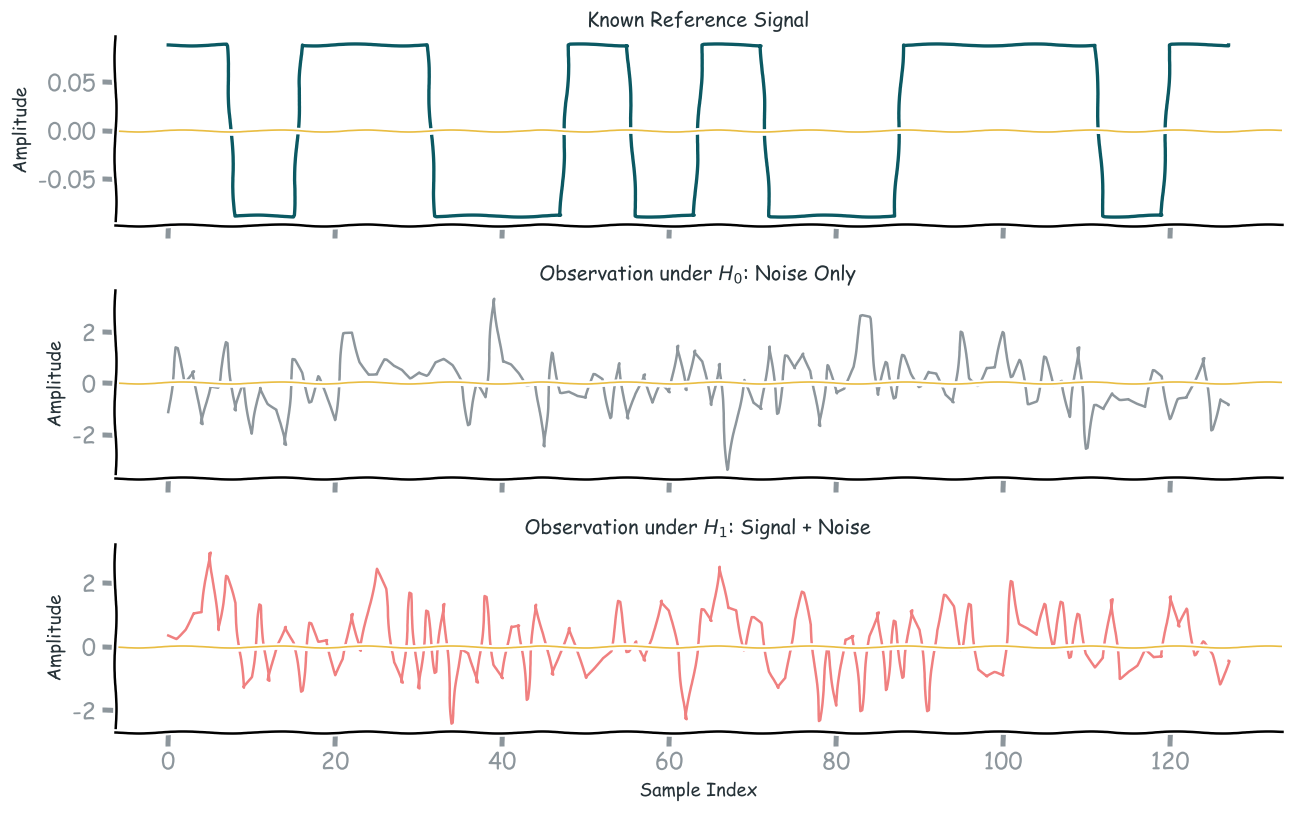

Signal length: 128 samples
Reference energy: 1.000
Signal amplitude A: 2.0
Noise standard deviation: 1.0


In [5]:
rng_signal = np.random.default_rng(BASE_SEED + 101)

# A short, known BPSK-style preamble
chips = np.array([
     1, -1,  1,  1,
    -1, -1,  1, -1,
     1, -1, -1,  1,
     1,  1, -1,  1
], dtype=float)

samples_per_chip = 8

s = np.repeat(chips, samples_per_chip)

s = s / np.linalg.norm(s)

N = len(s)

# Signal and noise parameters
A = 2.0
sigma = 1.0

n0 = sigma * rng_signal.standard_normal(N)
n1 = sigma * rng_signal.standard_normal(N)

# Observations under the two hypotheses
y0 = n0
y1 = A * s + n1

# Visualize
fig, axes = plt.subplots(
    3, 1, figsize=(11, 7), sharex=True
)

axes[0].plot(s, color=TEAL, lw=2)
axes[0].set_title("Known Reference Signal")
axes[0].set_ylabel("Amplitude")

axes[1].plot(y0, color=GRAY, lw=1.5)
axes[1].set_title(r"Observation under $H_0$: Noise Only")
axes[1].set_ylabel("Amplitude")

axes[2].plot(y1, color=RED, lw=1.5)
axes[2].set_title(r"Observation under $H_1$: Signal + Noise")
axes[2].set_ylabel("Amplitude")
axes[2].set_xlabel("Sample Index")

for ax in axes:
    ax.axhline(0, color=YELLOW, lw=1)
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

print(f"Signal length: {N} samples")
print(f"Reference energy: {np.dot(s, s):.3f}")
print(f"Signal amplitude A: {A}")
print(f"Noise standard deviation: {sigma}")


>***Q1:** Suppose we want to detect weaker signals by lowering the decision threshold. What happens to:*
> 1. *The probability of correctly detecting a transmitted signal?*
> 2. *The probability of generating a false alarm?*
>
>*Can we improve one without affecting the other?*

### 1.2 From Likelihood Ratios to Matched Filtering

#### The Likelihood-Ratio Test (LRT)

Under the Gaussian observation model, the conditional densities are
$$
p(\mathbf y|H_0) =
\frac{1}{(2\pi\sigma^2)^{N/2}}
\exp\left(
-\frac{\|\mathbf y\|_2^2}{2\sigma^2}
\right),
$$
and
$$
p(\mathbf y|H_1)=
\frac{1}{(2\pi\sigma^2)^{N/2}}
\exp\left(
-\frac{\|\mathbf y-A\mathbf s\|_2^2}{2\sigma^2}
\right).
$$
The likelihood ratio compares how well the two hypotheses explain the observation:
$$
\Lambda(\mathbf y) =
\frac{p(\mathbf y|H_1)}
{p(\mathbf y|H_0)}.
$$
A likelihood-ratio test (LRT) decides $H_1$ when
$$
\Lambda(\mathbf y)>\eta,
$$
where $\eta$ is a decision threshold.

Because the logarithm is monotonic, we can equivalently use the log-likelihood ratio:
$$
\ell(\mathbf y) =
\log p(\mathbf y|H_1) -
\log p(\mathbf y|H_0).
$$
Substituting the Gaussian densities gives
$$
\ell(\mathbf y) =
\frac{
\|\mathbf y\|_2^2 -
\|\mathbf y-A\mathbf s\|_2^2
}
{2\sigma^2}.
$$
Expanding
$$
\|\mathbf y-A\mathbf s\|_2^2 =
\|\mathbf y\|_2^2
-2A\mathbf s^T\mathbf y
+A^2\|\mathbf s\|_2^2,
$$
we obtain
$$
\boxed{
\ell(\mathbf y) =
\frac{A}{\sigma^2}\mathbf s^T\mathbf y -
\frac{A^2}{2\sigma^2}\|\mathbf s\|_2^2.
}
$$
For known $A>0$, this expression is an increasing function of
$$
\boxed{T(\mathbf y)=\mathbf s^T\mathbf y.}
$$
Therefore, the LRT is equivalent to comparing the **matched-filter output** with a threshold:
$$
T(\mathbf y)
\underset{H_0}{\overset{H_1}{\gtrless}}
\gamma.
$$

The matched filter computes the inner product between the received observation and the known waveform.
A large positive inner product provides evidence that the expected waveform is present.

The result is important because it connects classical signal processing to statistical inference:  
> Under the assumed Gaussian model, the matched filter is not simply a convenient similarity measure; it is the statistic that appears in the optimal likelihood-ratio test.

The specific threshold depends on the decision criterion.

#### Normalizing the Detection Statistic

The matched-filter output is
$$
T(\mathbf y)=\mathbf s^T\mathbf y.
$$
Under $H_0$,
$$
T|H_0\sim
\mathcal N\left(
0,\sigma^2\|\mathbf s\|_2^2
\right).
$$
Under $H_1$,
$$
T|H_1\sim
\mathcal N\left(
A\|\mathbf s\|_2^2,
\sigma^2\|\mathbf s\|_2^2
\right).
$$
To simplify comparisons, we define a normalized statistic:
$$
\boxed{
Z(\mathbf y)=
\frac{\mathbf s^T\mathbf y}
{\sigma\|\mathbf s\|_2}.
}
$$
It follows that
$$
Z|H_0\sim\mathcal N(0,1),
$$
and
$$
Z|H_1\sim\mathcal N(d,1),
$$
where
$$
\boxed{
d=\frac{A\|\mathbf s\|_2}{\sigma}.
}
$$
The parameter $d$ measures the separation between the two score distributions in units of their common standard deviation.
Its square equals the signal-energy-to-noise-variance ratio in this model:
$$
\mathrm{SNR}=
\frac{A^2\|\mathbf s\|_2^2}{\sigma^2}
=d^2.
$$
We can now write the decision rule as
$$
Z(\mathbf y)
\underset{H_0}{\overset{H_1}{\gtrless}}
\tau.
$$

#### Detection and False-Alarm Probabilities

For a normalized threshold $\tau$,
$$
P_{FA} =
P(Z>\tau|H_0) =
Q(\tau),
$$
and
$$
P_D =
P(Z>\tau|H_1) =
Q(\tau-d).
$$
Here, $Q(x)=1-\Phi(x)$ is the upper-tail probability of the standard normal distribution.

In SciPy, this is implemented as `norm.sf(x)`.

> **Note:** These expressions are exact for our specified Gaussian model with known parameters.


### 1.3 Detection Thresholds and Score Distributions

#### Choose a Neyman–Pearson Threshold

In [6]:
# Desired false-alarm probability
alpha = 0.05

# Normalized threshold
tau = norm.isf(alpha)

d = A * np.linalg.norm(s) / sigma

pfa_theory = norm.sf(tau)
pd_theory = norm.sf(tau - d)

z0 = np.dot(s, y0) / (sigma * np.linalg.norm(s))
z1 = np.dot(s, y1) / (sigma * np.linalg.norm(s))

print(f"Normalized threshold: {tau:.4f}")
print(f"Separation d: {d:.4f}")
print(f"Theoretical P_FA: {pfa_theory:.4f}")
print(f"Theoretical P_D:  {pd_theory:.4f}")

print("\nSingle-observation decisions:")
print(f"H0 observation: score={z0:.3f}, "
      f"decision={'H1' if z0 > tau else 'H0'}")

print(f"H1 observation: score={z1:.3f}, "
      f"decision={'H1' if z1 > tau else 'H0'}")


Normalized threshold: 1.6449
Separation d: 2.0000
Theoretical P_FA: 0.0500
Theoretical P_D:  0.6388

Single-observation decisions:
H0 observation: score=-0.493, decision=H0
H1 observation: score=3.441, decision=H1


#### Monte Carlo Evaluation

A decision based on one observation cannot tell us how reliable a detector is.
Instead, we generate many independent observations under each hypothesis and evaluate the detector statistically.

Let
$$
\{Z_i^{(0)}\}_{i=1}^{M}
$$
denote scores generated under $H_0$, and
$$
\{Z_i^{(1)}\}_{i=1}^{M}
$$
denote scores generated under $H_1$.

For a fixed threshold $\tau$, the empirical false-alarm probability is
$$
\widehat P_{FA}=
\frac{1}{M}
\sum_{i=1}^{M}
\mathbb I\left(Z_i^{(0)}>\tau\right),
$$
while the empirical detection probability is
$$
\widehat P_D=
\frac{1}{M}
\sum_{i=1}^{M}
\mathbb I\left(Z_i^{(1)}>\tau\right).
$$
Here, $\mathbb I(\cdot)$ is the indicator function.

As the number of independent simulations increases, the empirical probabilities should approach their theoretical values.

#### Simulate the Detector

Detector performance
------------------------------------------------
                        Theoretical  Empirical
False-alarm probability       0.0500     0.0517
Detection probability        0.6388     0.6369


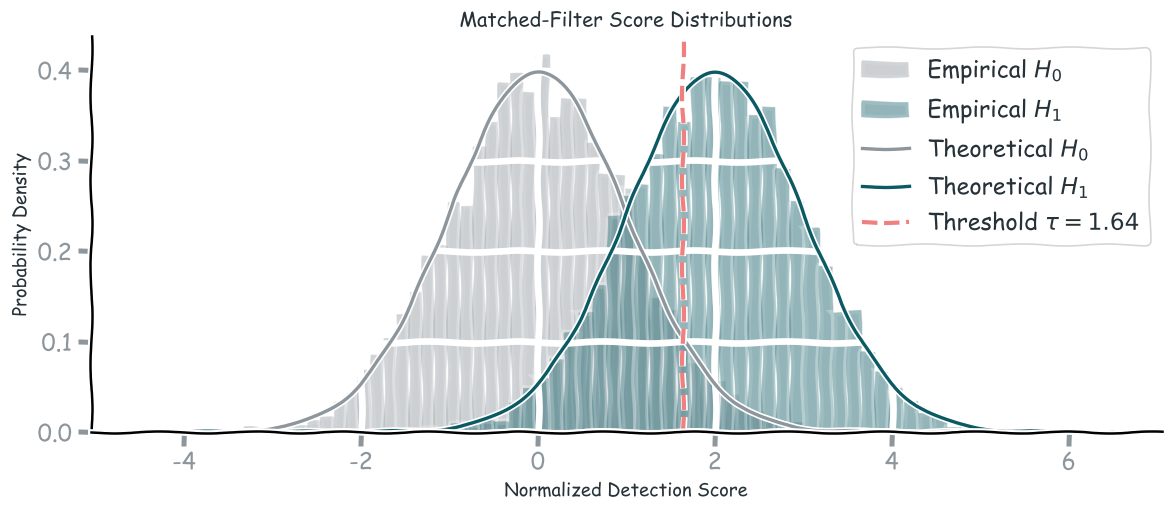

In [7]:
# Monte Carlo 
rng_mc = np.random.default_rng(BASE_SEED + 102)

n_trials = 8000

# Observations under H0 and H1
Y0 = sigma * rng_mc.standard_normal((n_trials, N))

Y1 = (
    A * s
    + sigma * rng_mc.standard_normal((n_trials, N))
)

normalization = sigma * np.linalg.norm(s)

Z0 = (Y0 @ s) / normalization
Z1 = (Y1 @ s) / normalization

pfa_emp = np.mean(Z0 > tau)
pd_emp = np.mean(Z1 > tau)

print("Detector performance")
print("-" * 48)
print(f"{'':22s} {'Theoretical':>12s} {'Empirical':>10s}")
print(f"{'False-alarm probability':22s} "
      f"{pfa_theory:12.4f} {pfa_emp:10.4f}")
print(f"{'Detection probability':22s} "
      f"{pd_theory:12.4f} {pd_emp:10.4f}")

# Plot 
z_axis = np.linspace(-4.5, d + 4.5, 600)

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.hist(
    Z0, bins=50, density=True,
    alpha=0.25, color=GRAY,
    label=r"Empirical $H_0$"
)

ax.hist(
    Z1, bins=50, density=True,
    alpha=0.25, color=TEAL,
    label=r"Empirical $H_1$"
)

ax.plot(
    z_axis, norm.pdf(z_axis),
    color=GRAY, lw=2,
    label=r"Theoretical $H_0$"
)

ax.plot(
    z_axis, norm.pdf(z_axis, loc=d),
    color=TEAL, lw=2,
    label=r"Theoretical $H_1$"
)

ax.axvline(
    tau, color=RED, lw=2.5,
    linestyle="--",
    label=rf"Threshold $\tau={tau:.2f}$"
)

ax.set_xlabel("Normalized Detection Score")
ax.set_ylabel("Probability Density")
ax.set_title("Matched-Filter Score Distributions")
ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


The detector converts a high-dimensional waveform into a single scalar score.  
Under the assumed model, this score follows a Gaussian distribution whose mean depends on whether the signal is present.

Several important observations follow.  

**1. The two distributions overlap.**  
Even an optimal detector cannot classify every observation correctly when noise makes the hypotheses difficult to distinguish.

**2. The threshold determines the operating point.**  
Moving the threshold to the left increases the fraction of observations classified as $H_1$ under both hypotheses.  
Therefore, lowering the threshold increases both $P_D$ and $P_{FA}$.

**3. The separation between the distributions depends on SNR.**  
Increasing $A/\sigma$ moves the $H_1$ score distribution farther from $H_0$, making detection easier.

**4. Empirical performance approaches theoretical performance.**  
The Monte Carlo results should be close to the theoretical probabilities, although finite-sample fluctuations are expected.

**Note:**  
> A detector's **score function** and its **decision threshold** are not the same thing. The score determines how observations are ranked by evidence for the signal. The threshold determines which observations are declared positive.

This distinction also appears in machine learning classifiers, where a model may output a probability or score that is subsequently converted into a class label.

### 1.4 ROC Curves

#### Receiver Operating Characteristic (ROC)

A single threshold produces one operating point:
$$
(P_{FA}(\tau),P_D(\tau)).
$$
By varying the threshold, we obtain the Receiver Operating Characteristic (ROC) curve.
For our Gaussian detector,
$$
P_{FA}(\tau)=Q(\tau),
$$
and
$$
P_D(\tau)=Q(\tau-d).
$$
Since
$$
\tau=Q^{-1}(P_{FA}),
$$
we can eliminate the threshold to obtain
$$
\boxed{
P_D =
Q\left(Q^{-1}(P_{FA})-d\right).
}
$$
This is the theoretical ROC curve for our model.

The ROC curve describes the relationship between detection probability and false-alarm probability across all decision thresholds.
A detector whose ROC lies closer to the upper-left corner generally provides better discrimination.  
For a fixed score function, changing the threshold moves the operating point along the same ROC curve. it does not create a different underlying curve.  
By contrast, improving the quality of the score function or increasing the effective SNR may improve the entire ROC.


#### Compare Theoretical and Empirical ROC

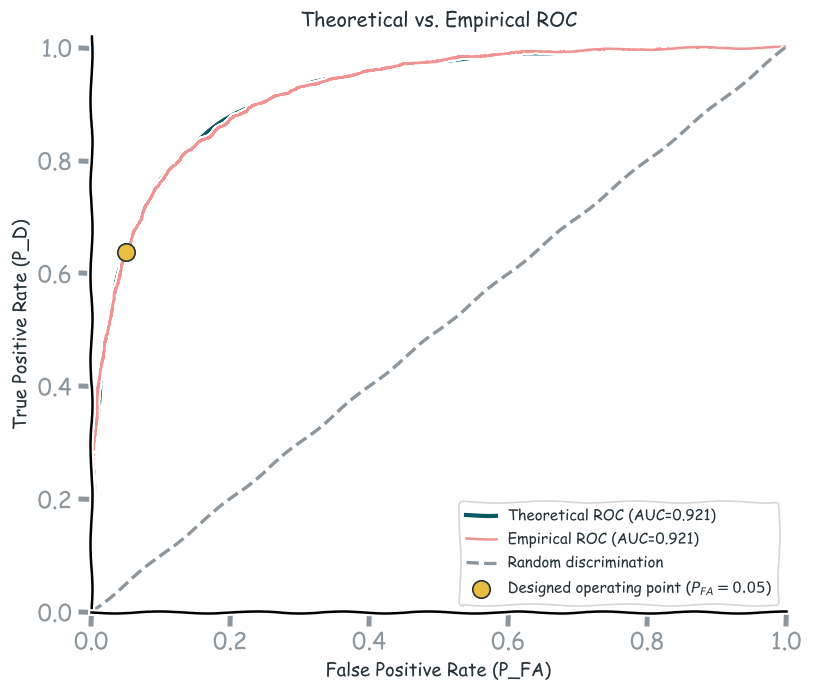

Theoretical ROC-AUC: 0.9214
Empirical ROC-AUC:   0.9208


In [8]:
from sklearn.metrics import roc_curve, roc_auc_score

# True labels and detection scores
labels = np.concatenate([
    np.zeros(n_trials, dtype=int),
    np.ones(n_trials, dtype=int)
])

scores = np.concatenate([Z0, Z1])

# Empirical ROC
fpr_emp, tpr_emp, thresholds = roc_curve(
    labels, scores
)

auc_emp = roc_auc_score(labels, scores)

# Theoretical ROC
tau_grid = np.linspace(6, -5, 500)

fpr_theory = norm.sf(tau_grid)
tpr_theory = norm.sf(tau_grid - d)

auc_theory = norm.cdf(d / np.sqrt(2))

# Plot
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr_theory, tpr_theory,
    color=TEAL, lw=2.5,
    label=rf"Theoretical ROC (AUC={auc_theory:.3f})"
)

ax.plot(
    fpr_emp, tpr_emp,
    color=RED, lw=1.5, alpha=0.85,
    label=rf"Empirical ROC (AUC={auc_emp:.3f})"
)

ax.plot(
    [0, 1], [0, 1],
    color=GRAY, linestyle="--",
    label="Random discrimination"
)

ax.scatter(
    [alpha], [pd_theory],
    color=YELLOW, edgecolor=DARK,
    s=110, zorder=5,
    label=rf"Designed operating point ($P_{{FA}}={alpha:.2f}$)"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel("False Positive Rate (P_FA)")
ax.set_ylabel("True Positive Rate (P_D)")
ax.set_title("Theoretical vs. Empirical ROC")

ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

print(f"Theoretical ROC-AUC: {auc_theory:.4f}")
print(f"Empirical ROC-AUC:   {auc_emp:.4f}")


### 1.5 Optional: Effect of SNR on Detection

The separation between the normalized score distributions is
$$
d=\frac{A\|\mathbf s\|_2}{\sigma}.
$$
We defined the signal-energy-to-noise-variance ratio as
$$
\mathrm{SNR}=d^2.
$$
Expressed in decibels,
$$
\mathrm{SNR}_{dB}=
10\log_{10}(d^2).
$$
At a fixed false-alarm requirement $P_{FA}=\alpha$, the normalized threshold is
$$
\tau_\alpha=Q^{-1}(\alpha).
$$
Therefore,
$$
\boxed{
P_D(\alpha,d)=
Q\left(Q^{-1}(\alpha)-d\right).
}
$$
We expect detection probability to increase as SNR increases.

Because the normalized score distributions are already known, we can simulate their scalar outputs directly instead of generating the full received waveform at every SNR.


#### Detection Probability vs. SNR

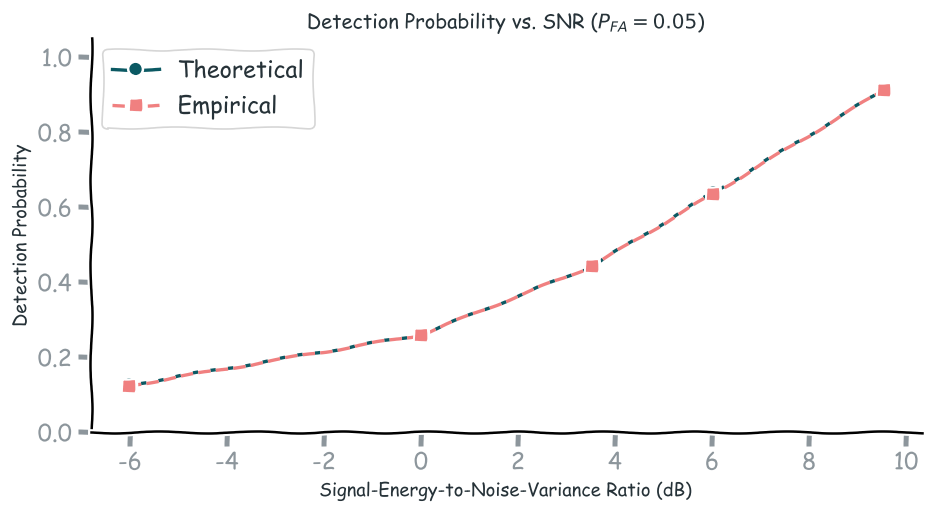

  SNR (dB)    Theory PD   Empirical PD
     -6.02       0.1261         0.1239
     -0.00       0.2595         0.2592
      3.52       0.4424         0.4421
      6.02       0.6388         0.6351
      9.54       0.9123         0.9123


In [9]:
rng_snr = np.random.default_rng(BASE_SEED + 103)

# Signal amplitudes
A_values = np.array([0.5, 1.0, 1.5, 2.0, 3.0])

d_values = A_values * np.linalg.norm(s) / sigma

snr_db = 10 * np.log10(d_values**2)

alpha_snr = 0.05
tau_snr = norm.isf(alpha_snr)

pd_snr_theory = norm.sf(tau_snr - d_values)

n_snr_trials = 8000

Z1_snr = (
    rng_snr.standard_normal(
        (n_snr_trials, len(d_values))
    )
    + d_values
)

pd_snr_emp = np.mean(Z1_snr > tau_snr, axis=0)

# Plot
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    snr_db, pd_snr_theory,
    color=TEAL, marker="o", lw=2,
    label="Theoretical"
)

ax.plot(
    snr_db, pd_snr_emp,
    color=RED, marker="s", linestyle="--",
    label="Empirical"
)

ax.set_xlabel("Signal-Energy-to-Noise-Variance Ratio (dB)")
ax.set_ylabel("Detection Probability")
ax.set_title(
    rf"Detection Probability vs. SNR ($P_{{FA}}={alpha_snr:.2f}$)"
)

ax.set_ylim(0, 1.05)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

print(f"{'SNR (dB)':>10} "
      f"{'Theory PD':>12} {'Empirical PD':>14}")

for snr, pdt, pde in zip(
    snr_db, pd_snr_theory, pd_snr_emp
):
    print(f"{snr:10.2f} {pdt:12.4f} {pde:14.4f}")


The experiment shows that increasing signal strength relative to noise makes the two hypotheses easier to distinguish.
For a fixed false-alarm requirement, higher SNR generally allows greater detection probability.
This leads to an important engineering distinction:
- **Changing the threshold** changes the operating point along a fixed ROC curve.
- **Changing the SNR** changes the underlying score distributions and therefore the ROC curve itself.

For a known signal in AWGN, the matched filter efficiently combines information across the observed samples.  
This explains why detecting a structured waveform can be possible even when the signal is difficult to identify visually in the raw observation.

### 1.6 Optional: Neyman–Pearson and Bayesian Detection

An important question remains:

**How should we choose the detection threshold?**

The answer depends on the objective of the detection system.

#### Neyman–Pearson Criterion

The Neyman–Pearson criterion maximizes detection probability subject to an upper bound on false-alarm probability:
$$
\boxed{
\max_\delta P_D(\delta)
\quad
\text{subject to}
\quad
P_{FA}(\delta)\leq\alpha.
}
$$
For simple hypotheses, the Neyman–Pearson lemma establishes that an appropriately thresholded likelihood-ratio test is most powerful at the specified false-alarm level.

In our Gaussian example,
$$
\tau_\alpha=Q^{-1}(\alpha).
$$
This threshold is chosen without requiring prior probabilities for the two hypotheses.

#### Bayesian Decision Criterion

In Bayesian detection, we can instead use prior probabilities and the costs associated with different decisions.

Let
$$
\pi_0=P(H_0),\qquad \pi_1=P(H_1).
$$
For equal misclassification costs and zero cost for correct decisions, the minimum-error decision rule selects $H_1$ when
$$
P(H_1|\mathbf y)>P(H_0|\mathbf y).
$$
Using Bayes' rule, this becomes
$$
\boxed{
\Lambda(\mathbf y)>\frac{\pi_0}{\pi_1}.
}
$$
Equivalently,
$$
\ell(\mathbf y)>
\log\left(\frac{\pi_0}{\pi_1}\right).
$$
More general misclassification costs lead to different likelihood-ratio thresholds.

#### Connection to Machine Learning

This distinction will appear again when we introduce learned classifiers.
A classifier may estimate
$$
P(H_1|\mathbf x),
$$
but converting that probability into a final decision still requires choosing a threshold.

The appropriate threshold may depend on class prevalence, misclassification costs, and operational constraints.

**Note:**   
>A model and a decision policy are related, but they are not identical.

### 1.7 Optional: Unknown Amplitude Signal

#### Generalized Likelihood-Ratio Test (GLRT)

So far, we assumed that the transmitted amplitude $A$ is known.
What if the waveform is known but its amplitude is unknown?
Our hypotheses become
$$
H_0:\mathbf y=\mathbf n,
$$
$$
H_1:\mathbf y=A\mathbf s+\mathbf n.
$$
The difference is that $A$ is now an unknown nuisance parameter under $H_1$.

A common approach is the **Generalized Likelihood-Ratio Test (GLRT)**:
$$
\Lambda_{\mathrm{GLRT}}(\mathbf y) =
\frac{
\max_A p(\mathbf y|H_1,A)
}{
p(\mathbf y|H_0)
}.
$$
Assume initially that $A$ can be any real number.
The maximum-likelihood estimate under $H_1$ is
$$
\hat A =
\arg\min_A
\|\mathbf y-A\mathbf s\|_2^2.
$$
Solving gives
$$
\boxed{
\hat A=\frac{\mathbf s^T\mathbf y}{\mathbf s^T\mathbf s}.
}
$$
Substituting this estimate into the likelihood ratio gives
$$
\log\Lambda_{\mathrm{GLRT}}(\mathbf y) =
\frac{(\mathbf s^T\mathbf y)^2}
{2\sigma^2\mathbf s^T\mathbf s}.
$$
Therefore, an equivalent GLRT statistic is
$$
\boxed{
T_{\mathrm{GLRT}}(\mathbf y) =
\frac{(\mathbf s^T\mathbf y)^2}
{\mathbf s^T\mathbf s}.
}
$$
Notice the difference:
- When a positive amplitude is known, the LRT uses the signed matched-filter output.
- When the amplitude is unknown and may be positive or negative, the GLRT uses a squared matched-filter output.

This happens because either sign can support the unrestricted alternative hypothesis.

**Important qualification:** If the unknown amplitude is constrained to $A\geq0$, its maximum-likelihood estimate becomes
$$
\hat A=
\max\left(
0,\frac{\mathbf s^T\mathbf y}{\mathbf s^T\mathbf s}
\right),
$$

and the resulting GLRT is based on the positive part of the matched-filter output, not on an unrestricted squared statistic.

>**Connection to Week 1:**  
>The GLRT demonstrates how parameter estimation and hypothesis testing can be combined:
>$$
>\boxed{
>\text{Observation}
>\rightarrow
>\text{Parameter Estimation}
>\rightarrow
>\text{Statistical Decision}
>}
>$$
>The unknown amplitude is first estimated and then used to evaluate how strongly the alternative model explains the observation.

### 1.8 Optional: Detection in Colored Gaussian Noise

Our original matched-filter detector assumes white Gaussian noise:
$$
\mathbf n\sim\mathcal N(\mathbf 0,\sigma^2\mathbf I).
$$
However, practical measurement noise may have temporal correlation.
Suppose instead
$$
\mathbf n\sim\mathcal N(\mathbf 0,\mathbf C),
$$
where $\mathbf C$ is a positive-definite noise covariance matrix.
The hypotheses remain
$$
H_0:\mathbf y=\mathbf n,
$$
$$
H_1:\mathbf y=A\mathbf s+\mathbf n.
$$
Under these assumptions, the Gaussian log-likelihood ratio contains the statistic
$$
\boxed{
T_{\mathrm{opt}}(\mathbf y) =
\mathbf s^T\mathbf C^{-1}\mathbf y.
}
$$
The covariance inverse changes how different directions in the observation space contribute to the detection score.  
Directions containing high noise variance or strong noise correlation are weighted differently from more reliable directions.

This leads to the **generalized (whitened) matched filter**.  
Define the whitened variables
$$
\tilde{\mathbf y} =
\mathbf C^{-1/2}\mathbf y,
$$
$$
\tilde{\mathbf s} =
\mathbf C^{-1/2}\mathbf s.
$$
Then
$$
T_{\mathrm{opt}}(\mathbf y) =
\tilde{\mathbf s}^T\tilde{\mathbf y}.
$$
Thus, the detector can be interpreted as applying a matched filter after whitening the noise.  
We will compare the ordinary correlation statistic with the covariance-aware statistic on simulated colored noise.
Both statistics will be normalized to have unit variance under $H_0$.

#### Ordinary vs Whitened Detectors

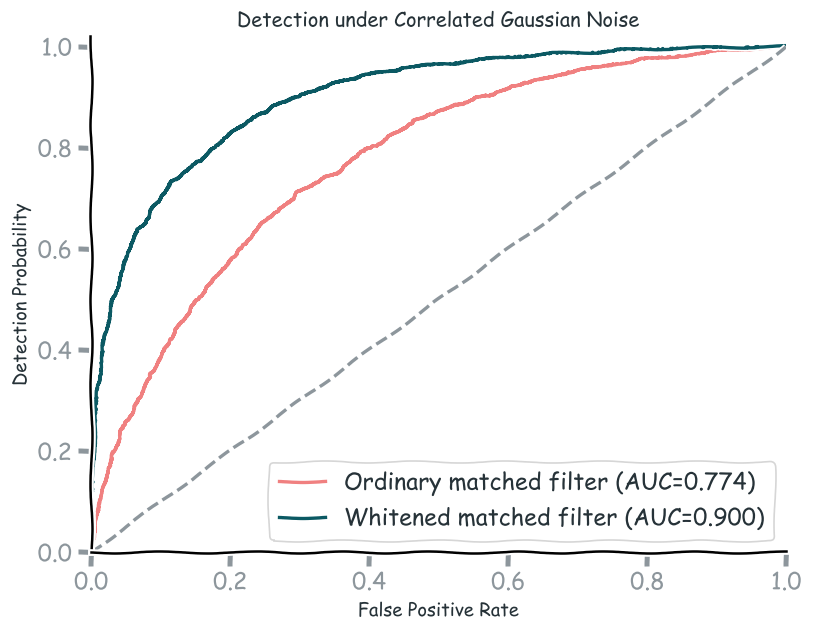

Ordinary matched-filter AUC: 0.7742
Whitened matched-filter AUC: 0.9001


In [10]:
rng_colored = np.random.default_rng(BASE_SEED + 104)

# Correlated Gaussian noise covariance
rho = 0.8

indices = np.arange(N)

C = sigma**2 * rho**np.abs(
    indices[:, None] - indices[None, :]
)

L = np.linalg.cholesky(C)

n_colored_trials = 3000

N0 = rng_colored.standard_normal(
    (n_colored_trials, N)
) @ L.T

N1 = rng_colored.standard_normal(
    (n_colored_trials, N)
) @ L.T

Y0_colored = N0
Y1_colored = A * s + N1

# Ordinary matched-filter score
ordinary_scale = np.sqrt(s @ C @ s)

Z0_ordinary = (Y0_colored @ s) / ordinary_scale
Z1_ordinary = (Y1_colored @ s) / ordinary_scale

# Covariance-aware matched-filter score
w = np.linalg.solve(C, s)

optimal_scale = np.sqrt(s @ w)

Z0_optimal = (Y0_colored @ w) / optimal_scale
Z1_optimal = (Y1_colored @ w) / optimal_scale

# ROC comparison
labels_colored = np.concatenate([
    np.zeros(n_colored_trials, dtype=int),
    np.ones(n_colored_trials, dtype=int)
])

scores_ordinary = np.concatenate([
    Z0_ordinary, Z1_ordinary
])

scores_optimal = np.concatenate([
    Z0_optimal, Z1_optimal
])

fpr_ord, tpr_ord, _ = roc_curve(
    labels_colored, scores_ordinary
)

fpr_opt, tpr_opt, _ = roc_curve(
    labels_colored, scores_optimal
)

auc_ord = roc_auc_score(
    labels_colored, scores_ordinary
)

auc_opt = roc_auc_score(
    labels_colored, scores_optimal
)

fig, ax = plt.subplots(figsize=(7, 5.5))

ax.plot(
    fpr_ord, tpr_ord,
    color=RED, lw=2,
    label=rf"Ordinary matched filter (AUC={auc_ord:.3f})"
)

ax.plot(
    fpr_opt, tpr_opt,
    color=TEAL, lw=2,
    label=rf"Whitened matched filter (AUC={auc_opt:.3f})"
)

ax.plot(
    [0, 1], [0, 1],
    color=GRAY, linestyle="--"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("Detection Probability")
ax.set_title("Detection under Correlated Gaussian Noise")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.15)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"Ordinary matched-filter AUC: {auc_ord:.4f}")
print(f"Whitened matched-filter AUC: {auc_opt:.4f}")


In the colored-noise experiment, both detectors receive observations generated from the same statistical model.
However, they use different detection statistics.  
The ordinary matched filter calculates
$$
\mathbf s^T\mathbf y,
$$
while the covariance-aware matched filter calculates
$$
\mathbf s^T\mathbf C^{-1}\mathbf y.
$$
The second statistic uses information about the noise covariance.
Under the assumed Gaussian model, it is the likelihood-ratio-optimal linear detection statistic for known positive amplitude.
We therefore expect the covariance-aware detector to achieve better or equal population ROC performance.
The empirical curves may fluctuate because they are estimated from a finite number of observations.

### Experiment 1: Summary


We studied binary detection of a known signal in Gaussian noise.
The main results are:

**1. Statistical model**

$$
H_0:\mathbf y=\mathbf n,
\qquad
H_1:\mathbf y=A\mathbf s+\mathbf n.
$$

**2. Matched-filter detection**

For known positive amplitude and white Gaussian noise, the likelihood-ratio test is equivalent to thresholding

$$
T(\mathbf y)=\mathbf s^T\mathbf y.
$$

**3. Detection performance**

For the normalized matched-filter statistic,

$$
P_{FA}=Q(\tau),
\qquad
P_D=Q(\tau-d).
$$

**4. ROC curves**

An ROC curve characterizes the detection trade-off across decision thresholds.  
Changing the threshold moves the operating point along a fixed ROC; changing the effective SNR changes the ROC itself.

**5. Modeling assumptions**

When noise is correlated, covariance-aware detection can outperform the ordinary matched filter.

# Part II: Learning to Classify

## Experiment 2: Learning to Detect Abnormal ECG Beats

Now, what happens when the class-conditional probability distributions are unknown or difficult to describe?

One possible approach is to learn a classifier directly from labeled examples.
In this experiment, we will use real electrocardiogram (ECG) recordings to distinguish two types of heartbeats:

- **Normal beats (N):** Beats labeled as normal in the reference annotations.
- **Premature ventricular contractions (PVC, V):** Ventricular ectopic beats that occur prematurely relative to the usual cardiac rhythm.

We will represent each heartbeat using a small set of signal-processing features and train a logistic regression classifier.

### 2.1 Problem Formulation and Dataset Exploration

#### From Statistical Detection to Machine Learning

The detector uses a statistical model to calculate evidence for each hypothesis.
In many applications, however, the probability distributions $p(\mathbf y|H_0)$ and $p(\mathbf y|H_1)$ are not known.

Instead, suppose we have a labeled dataset
$$
\mathcal D=
\{(\mathbf x_i,y_i)\}_{i=1}^{M},
$$
where:
- $\mathbf x_i\in\mathbb R^d$ is a feature vector extracted from an observation.
- $y_i\in\{0,1\}$ is its class label.
- $M$ is the number of labeled examples.

Our goal is to learn a function
$$
f_{\boldsymbol\theta}:\mathbf x\mapsto \hat p,
$$
where $\hat p$ is a model-estimated probability of the positive class.
A decision threshold then converts this probability into a class label:
$$
\hat y=
\begin{cases}
1,&\hat p>\tau,\\
0,&\hat p\leq\tau.
\end{cases}
$$
This gives the general classification pipeline:
$$
\boxed{
\text{Raw Signal}
\rightarrow
\text{Feature Extraction}
\rightarrow
\text{Learned Model}
\rightarrow
\text{Decision}
}
$$

#### The MIT-BIH Arrhythmia Database

The MIT-BIH Arrhythmia Database is a widely used resource for studying automated ECG analysis.

It contains:
- 48 approximately 30-minute ECG recordings.
- Two ECG channels per recording.
- A sampling frequency of 360 Hz.
- Reference annotations identifying heartbeat types and other events.

Dataset: https://physionet.org/content/mitdb/1.0.0/

We will use a subset of eight records:

| Purpose | Record IDs |
|---|---|
| Training | 100, 106, 119, 200 |
| Validation | 203, 221 |
| Testing | 208, 233 |

The selected records contain different mixtures of normal and PVC beats.
We use the two annotation symbols:
$$
N\rightarrow y=0,
\qquad
V\rightarrow y=1.
$$
Other annotated beat types are excluded from this simplified binary classification task.

**Note:** 
>This is not a general normal-versus-abnormal ECG classifier. A beat labeled as neither `N` nor `V` is outside our current classification task.

#### Why Split by Recording? 

Consecutive heartbeats from the same recording are correlated and often share patient-specific morphology and measurement characteristics.
If we randomly mix beats from the same recording between training and testing, our evaluation may overestimate performance on genuinely unseen recordings.
We therefore use recording-separated partitions.

The split is fixed before training, and all model-dependent preprocessing will be fitted using training data only.
The held-out test recordings will not be used to select features, hyperparameters, or decision thresholds.

#### Loading the ECG Recordings

**Dataset Directory**

Place the downloaded files in the following directory, relative to the notebook:

`data/mitdb/`

For example, Record 100 should contain:
- `data/mitdb/100.dat`
- `data/mitdb/100.hea`
- `data/mitdb/100.atr`

The notebook reads these files using the Python `wfdb` package.

**Note:** If the files are stored elsewhere, update the `ECG_DIR` variable in the following code cell.

In [12]:
ECG_DIR = DATA_DIR / "mitdb"
ECG_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_RECORDS = ["100", "106", "119", "200"]
VAL_RECORDS = ["203", "221"]
TEST_RECORDS = ["208", "233"]

RECORD_IDS = (
    TRAIN_RECORDS + VAL_RECORDS + TEST_RECORDS
)

# Download only missing records
missing_records = [
    rid for rid in RECORD_IDS
    if not all(
        (ECG_DIR / f"{rid}.{ext}").exists()
        for ext in ("hea", "dat", "atr")
    )
]

if missing_records:
    print("Downloading missing recordings:", missing_records)

    wfdb.dl_database(
        "mitdb",
        dl_dir=str(ECG_DIR),
        records=missing_records,
        annotators=["atr"],
        overwrite=False
    )
else:
    print("All selected recordings are available locally.")

# Load ECG signals and annotations
ecg_records = {}

for rid in RECORD_IDS:
    record = wfdb.rdrecord(str(ECG_DIR / rid))
    annotation = wfdb.rdann(str(ECG_DIR / rid), "atr")

    # Use the MLII channel consistently
    if "MLII" not in record.sig_name:
        raise ValueError(
            f"Record {rid} does not contain an MLII channel."
        )

    channel_idx = record.sig_name.index("MLII")

    signal = record.p_signal[:, channel_idx]

    ecg_records[rid] = {
        "signal": signal,
        "fs": record.fs,
        "annotation": annotation,
        "channel": record.sig_name[channel_idx]
    }

    symbols = np.asarray(annotation.symbol)

    n_normal = np.sum(symbols == "N")
    n_pvc = np.sum(symbols == "V")

    print(
        f"Record {rid}: "
        f"fs={record.fs:.0f} Hz, "
        f"N={n_normal}, V={n_pvc}"
    )

print("\nDataset loading completed.")

All selected recordings are available locally.
Record 100: fs=360 Hz, N=2239, V=1
Record 106: fs=360 Hz, N=1507, V=520
Record 119: fs=360 Hz, N=1543, V=444
Record 200: fs=360 Hz, N=1743, V=826
Record 203: fs=360 Hz, N=2529, V=444
Record 221: fs=360 Hz, N=2031, V=396
Record 208: fs=360 Hz, N=1586, V=992
Record 233: fs=360 Hz, N=2230, V=831

Dataset loading completed.


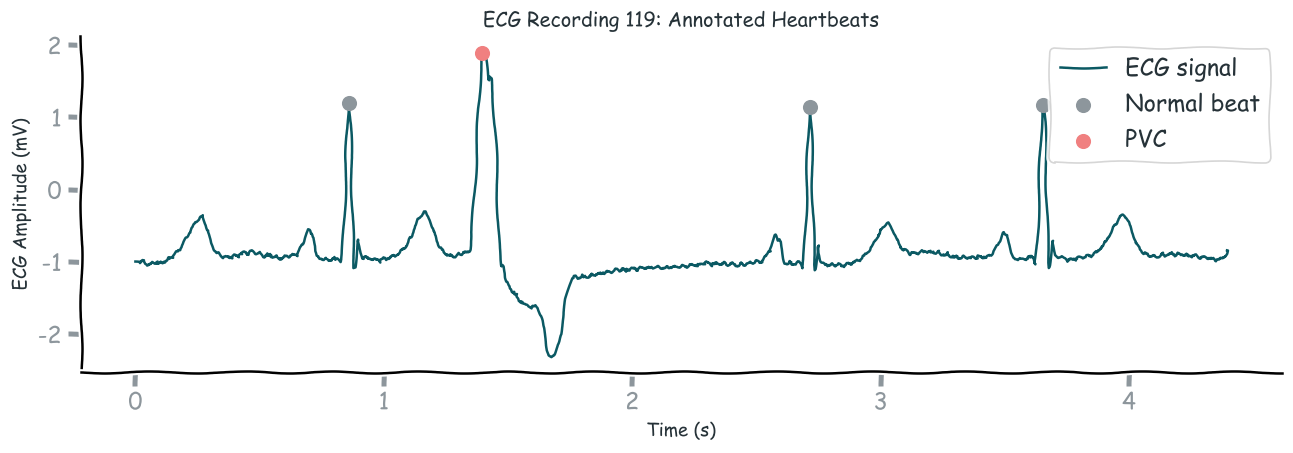

In [13]:
# Visualize a real ECG Recording
rid = "119"

signal = ecg_records[rid]["signal"]
fs = ecg_records[rid]["fs"]
ann = ecg_records[rid]["annotation"]

symbols = np.asarray(ann.symbol)
samples = np.asarray(ann.sample)

# Locate an annotated PVC
pvc_positions = samples[symbols == "V"]

if len(pvc_positions) == 0:
    raise ValueError("No PVC annotations found.")

center = int(pvc_positions[0])

# Display a short interval around the PVC
left = max(0, center - int(3 * fs))
right = min(len(signal), center + int(3 * fs))

t = np.arange(left, right) / fs

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(
    t, signal[left:right],
    color=TEAL, lw=1.5,
    label="ECG signal"
)

# Annotated normal and PVC beats
for symbol, color, label in [
    ("N", GRAY, "Normal beat"),
    ("V", RED, "PVC")
]:
    mask = (
        (symbols == symbol)
        & (samples >= left)
        & (samples < right)
    )

    positions = samples[mask]

    ax.scatter(
        positions / fs,
        signal[positions],
        color=color,
        s=65,
        zorder=5,
        label=label
    )

ax.set_title(f"ECG Recording {rid}: Annotated Heartbeats")
ax.set_xlabel("Time (s)")
ax.set_ylabel("ECG Amplitude (mV)")
ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

### 2.2 Feature Extraction

A classifier cannot directly use the raw ECG waveform unless we provide it with a suitable numerical representation.
One approach is to extract a small number of interpretable features from each heartbeat.

For example, we may describe a beat using:
- Its amplitude.
- Its local signal energy.
- Its waveform shape.
- Its duration-related characteristics.
- Its timing relative to previous beats.

In our experiment, the feature vector will be
$$
\mathbf x_i=
\begin{bmatrix}
RR_i &
A_i &
P_i &
R_i &
E_i &
S_i &
W_i
\end{bmatrix}^{T},
$$
where:
- $RR_i$: Previous RR interval.
- $A_i$: ECG amplitude at the annotated beat location, relative to a local baseline.
- $P_i$: Peak-to-peak amplitude in a local QRS window.
- $R_i$: Root-mean-square amplitude in the QRS window.
- $E_i$: Absolute signal area in the QRS window.
- $S_i$: Maximum absolute slope in the QRS window.
- $W_i$: A simple width-related feature.

These features describe different aspects of beat morphology and timing.

#### Beat Segmentation

The reference annotations provide the location of each heartbeat.
For a beat centered at sample $n_i$, we extract a waveform segment
$$
\mathbf b_i=
\left[
x[n_i-L],
\ldots,
x[n_i+R-1]
\right]^T.
$$
Here, $L$ and $R$ determine how much signal is retained before and after the annotated beat location.

We then calculate the features from this segment.

#### ECG Feature Extraction

In [14]:
FEATURE_NAMES = [
    "Previous RR (ms)",
    "R amplitude (mV)",
    "QRS peak-to-peak (mV)",
    "QRS RMS (mV)",
    "QRS absolute area (mV*s)",
    "Max QRS slope (mV/s)",
    "QRS width proxy (ms)"
]

# Annotation symbols corresponding to actual beat events
BEAT_SYMBOLS = {
    "N", "L", "R", "B",
    "A", "a", "J", "S",
    "V", "r", "F",
    "e", "j", "n", "E",
    "/", "f", "Q"
}

def extract_record_features(record_data, record_id):
    signal = record_data["signal"]
    fs = record_data["fs"]
    ann = record_data["annotation"]

    samples = np.asarray(ann.sample)
    symbols = np.asarray(ann.symbol)

    # Keep all beat annotations when computing RR intervals
    is_beat = np.isin(
        symbols, list(BEAT_SYMBOLS)
    )

    beat_samples = samples[is_beat]

    # Previous RR interval for each annotated beat
    rr_lookup = {
        int(beat_samples[i]):
        (beat_samples[i] - beat_samples[i - 1]) / fs
        for i in range(1, len(beat_samples))
    }

    # Beat window: 0.25 s before, 0.40 s after annotation
    pre = int(round(0.25 * fs))
    post = int(round(0.40 * fs))

    # Local QRS region around the annotation
    qrs_radius = int(round(0.12 * fs))

    features = []
    labels = []
    positions = []

    for pos, symbol in zip(samples, symbols):

        if symbol not in {"N", "V"}:
            continue

        pos = int(pos)

        if pos not in rr_lookup:
            continue

        start = pos - pre
        end = pos + post

        if start < 0 or end > len(signal):
            continue

        rr_prev = rr_lookup[pos]

        # Reject implausible intervals
        if not (0.2 <= rr_prev <= 3.0):
            continue

        segment = signal[start:end]

        # Local baseline estimate
        baseline = np.median(
            np.concatenate([
                segment[:20],
                segment[-20:]
            ])
        )

        segment_centered = segment - baseline

        qrs = segment_centered[
            pre - qrs_radius:
            pre + qrs_radius + 1
        ]

        # Signal-processing features
        rr_ms = 1000 * rr_prev

        r_amp = segment_centered[pre]

        qrs_ptp = np.ptp(qrs)

        qrs_rms = np.sqrt(np.mean(qrs**2))

        qrs_area = np.sum(np.abs(qrs)) / fs

        max_slope = fs * np.max(
            np.abs(np.diff(qrs))
        )

        peak_abs = np.max(np.abs(qrs))

        if peak_abs > 0:
            width_proxy = (
                1000 / fs
                * np.sum(
                    np.abs(qrs) >= 0.35 * peak_abs
                )
            )
        else:
            width_proxy = 0.0

        feature_vector = [
            rr_ms,
            r_amp,
            qrs_ptp,
            qrs_rms,
            qrs_area,
            max_slope,
            width_proxy
        ]

        if not np.all(np.isfinite(feature_vector)):
            continue

        features.append(feature_vector)
        labels.append(1 if symbol == "V" else 0)
        positions.append(pos)

    return (
        np.asarray(features, dtype=float),
        np.asarray(labels, dtype=int),
        np.full(len(labels), record_id),
        np.asarray(positions, dtype=int)
    )


all_features = []
all_labels = []
all_groups = []
all_positions = []

for rid in RECORD_IDS:
    X_r, y_r, g_r, p_r = extract_record_features(
        ecg_records[rid], rid
    )

    all_features.append(X_r)
    all_labels.append(y_r)
    all_groups.append(g_r)
    all_positions.append(p_r)

X_ecg = np.vstack(all_features)
y_ecg = np.concatenate(all_labels)
groups_ecg = np.concatenate(all_groups)
positions_ecg = np.concatenate(all_positions)

print("Feature extraction completed.")
print(f"Feature matrix shape: {X_ecg.shape}")
print(f"Number of classes: {len(np.unique(y_ecg))}")
print(f"Number of recordings: {len(np.unique(groups_ecg))}")
print(f"Normal beats: {np.sum(y_ecg == 0)}")
print(f"PVC beats: {np.sum(y_ecg == 1)}")

assert X_ecg.shape[1] == len(FEATURE_NAMES)
assert np.all(np.isfinite(X_ecg))
assert set(np.unique(y_ecg)) == {0, 1}

Feature extraction completed.
Feature matrix shape: (19851, 7)
Number of classes: 2
Number of recordings: 8
Normal beats: 15399
PVC beats: 4452


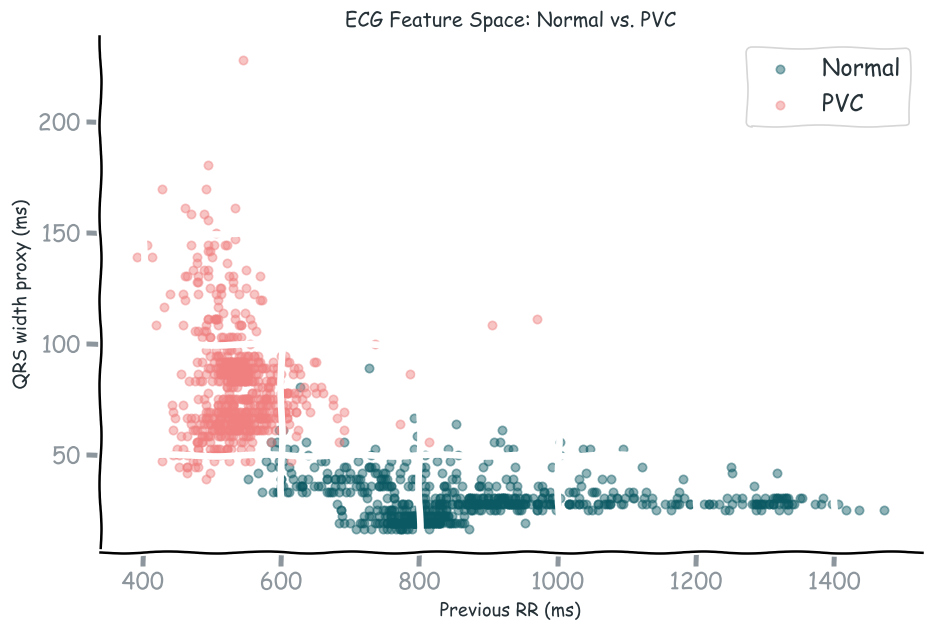

In [25]:
# Visualizing the Feature Space
train_mask = np.isin(groups_ecg, TRAIN_RECORDS)

X_preview = X_ecg[train_mask]
y_preview = y_ecg[train_mask]

rng_preview = np.random.default_rng(BASE_SEED + 201)

fig, ax = plt.subplots(figsize=(8, 5.5))

for cls, color, label in [
    (0, TEAL, "Normal"),
    (1, RED, "PVC")
]:
    idx = np.flatnonzero(y_preview == cls)

    # Use a limited subset for a clear visualization
    selected = rng_preview.choice(
        idx,
        size=min(700, len(idx)),
        replace=False
    )

    ax.scatter(
        X_preview[selected, 0],
        X_preview[selected, 6],
        color=color,
        alpha=0.45,
        s=25,
        label=label
    )

ax.set_xlabel(FEATURE_NAMES[0])
ax.set_ylabel(FEATURE_NAMES[6])
ax.set_title("ECG Feature Space: Normal vs. PVC")

ax.legend()
ax.grid(color=GRAY)

plt.tight_layout()
plt.show()

The feature visualization shows how normal and PVC beats are distributed in a two-dimensional representation.
Some observations may be easier to distinguish than others.
However, two features may not contain all the useful information present in the original waveform.
A classifier can combine several features simultaneously:
$$
\mathbf x=
[x_1,x_2,\ldots,x_d]^T.
$$
This raises two important questions.

**1. Which features contain useful information for classification?**

Features that differ systematically between classes may help the model distinguish them.

**2. What happens when features have different numerical scales?**

For example, an RR interval measured in milliseconds may have values in the hundreds, while ECG amplitudes may be much smaller numerically.

For regularized models, the scales of input features affect how the penalty influences different coefficients.
We will therefore standardize the features before fitting logistic regression.

**Important:** Feature scaling parameters must be learned from the training data only.

In this experiment, we will use a scikit-learn pipeline to ensure that the same training-fitted transformation is applied consistently to validation and test data.

### 2.3 Learning a Decision Rule with Logistic Regression

Before training a classifier, we must define how its performance will be evaluated.
We use three separate datasets.

| Dataset | Purpose |
|---|---|
| Training | Learn model parameters |
| Validation | Select hyperparameters and the decision threshold |
| Test | Evaluate the finalized classifier |

The recordings are separated into three nonoverlapping sets.
The test set must not influence feature selection, hyperparameter tuning, preprocessing parameters, or threshold selection.

#### Feature Standardization

For each feature $j$, we calculate
$$
z_{ij} =
\frac{x_{ij}-\hat\mu_j}
{\hat\sigma_j},
$$
where $\hat\mu_j$ and $\hat\sigma_j$ are estimated using the training data.
The same values are then used to transform validation and test observations.
This is especially important when using regularization.

#### Create the Data Partitions

In [19]:
mask_train = np.isin(groups_ecg, TRAIN_RECORDS)
mask_val = np.isin(groups_ecg, VAL_RECORDS)
mask_test = np.isin(groups_ecg, TEST_RECORDS)

X_train = X_ecg[mask_train]
y_train = y_ecg[mask_train]

X_val = X_ecg[mask_val]
y_val = y_ecg[mask_val]

X_test = X_ecg[mask_test]
y_test = y_ecg[mask_test]

groups_train = groups_ecg[mask_train]
groups_val = groups_ecg[mask_val]
groups_test = groups_ecg[mask_test]

# Verify no recording overlap
assert set(groups_train).isdisjoint(groups_val)
assert set(groups_train).isdisjoint(groups_test)
assert set(groups_val).isdisjoint(groups_test)

# Each partition must contain both classes
for label, y_part in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    assert set(np.unique(y_part)) == {0, 1}

    prevalence = np.mean(y_part)

    print(
        f"{label:12s}: "
        f"{len(y_part):6d} beats | "
        f"PVC prevalence={prevalence:.3f}"
    )

Train       :   8817 beats | PVC prevalence=0.203
Validation  :   5398 beats | PVC prevalence=0.156
Test        :   5636 beats | PVC prevalence=0.323


#### Logistic Regression

We now learn a classifier that estimates the probability of the positive class from the extracted ECG features.
Logistic regression models
$$
\boxed{
P(Y=1|\mathbf x)=
\sigma(\mathbf w^T\mathbf x+b),
}
$$
where
$$
\sigma(t)=\frac{1}{1+e^{-t}}
$$
is the sigmoid function.

The expression
$$
z=\mathbf w^T\mathbf x+b
$$

is called the linear predictor or logit.  

The sigmoid maps this quantity into the interval $(0,1)$.
A larger predicted probability indicates stronger model evidence for the positive class.

Logistic regression estimates its parameters by minimizing a loss based on the observed class labels.
For binary classification, the standard loss is binary cross-entropy:
$$
\mathcal L=
-\frac{1}{M}
\sum_{i=1}^{M}
\left[
y_i\log p_i+
(1-y_i)\log(1-p_i)
\right].
$$
We will also use $L_2$ regularization to discourage excessively large coefficients.

In scikit-learn, the parameter `C` controls inverse regularization strength:
- Smaller `C` means stronger regularization.
- Larger `C` means weaker regularization.

We will choose `C` using validation log loss.

*The detailed derivation of logistic regression is provided in the optional mathematical section later in the notebook.*

#### Train and Select Logistic Regression

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

C_GRID = [0.01, 0.1, 1.0, 10.0]

validation_results = []
candidate_models = []

for C in C_GRID:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=C,
            penalty="l2",
            max_iter=2000,
            random_state=BASE_SEED
        )
    )

    model.fit(X_train, y_train)

    p_val = model.predict_proba(X_val)[:, 1]

    loss = log_loss(y_val, p_val)

    candidate_models.append(model)
    validation_results.append(loss)

# Select the model with minimum validation log loss
best_idx = int(np.argmin(validation_results))
best_C = C_GRID[best_idx]

ecg_model = candidate_models[best_idx]

print("Validation log-loss results")
print("-" * 35)

for C, loss in zip(C_GRID, validation_results):
    print(f"C={C:<6g} | Validation log loss={loss:.4f}")

print(f"\nSelected C: {best_C}")

p_train = ecg_model.predict_proba(X_train)[:, 1]
p_val = ecg_model.predict_proba(X_val)[:, 1]

print(f"Training log loss: {log_loss(y_train, p_train):.4f}")
print(f"Validation log loss: {log_loss(y_val, p_val):.4f}")


Validation log-loss results
-----------------------------------
C=0.01   | Validation log loss=0.3875
C=0.1    | Validation log loss=0.7150
C=1      | Validation log loss=1.4911
C=10     | Validation log loss=2.5935

Selected C: 0.01
Training log loss: 0.0283
Validation log loss: 0.3875


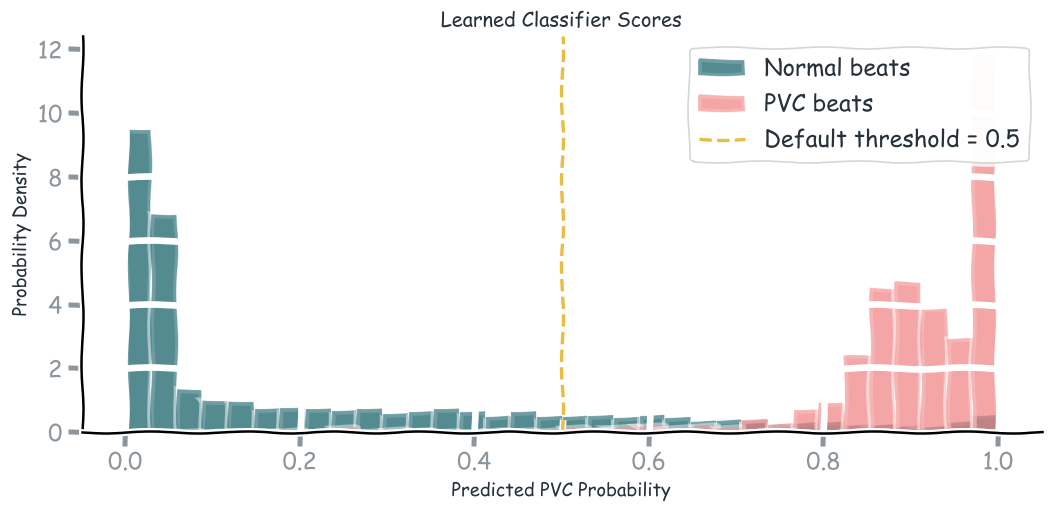

In [26]:
# Compare model scores across the two classes
fig, ax = plt.subplots(figsize=(9, 4.5))

bins = np.linspace(0, 1, 35)

ax.hist(
    p_val[y_val == 0],
    bins=bins,
    density=True,
    alpha=0.45,
    color=TEAL,
    label="Normal beats"
)

ax.hist(
    p_val[y_val == 1],
    bins=bins,
    density=True,
    alpha=0.45,
    color=RED,
    label="PVC beats"
)

ax.axvline(
    0.5,
    color=YELLOW,
    linestyle="--",
    lw=2,
    label="Default threshold = 0.5"
)

ax.set_xlabel("Predicted PVC Probability")
ax.set_ylabel("Probability Density")
ax.set_title("Learned Classifier Scores")

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()


Unlike the Gaussian detector in Experiment 1, logistic regression does not require us to specify separate probability distributions for the ECG features under each class.
Instead, it learns a relationship between feature vectors and class labels.
The model produces a continuous probability-like score:
$$
p_i=P_{\boldsymbol\theta}(Y=1|\mathbf x_i).
$$
To make a classification decision, we compare this score with a threshold.
For the default threshold $\tau=0.5$,
$$
\hat y_i=
\begin{cases}
1,&p_i>0.5,\\
0,&p_i\leq0.5.
\end{cases}
$$
However, $0.5$ is not necessarily the best threshold for every application.
For example, a system designed to detect rare events may require higher recall or stricter false-alarm control.
We therefore need to evaluate the classifier over different thresholds.

### 2.4 Evaluating the Classifier

We will evaluate the learned classifier using both ROC and precision–recall analysis.

#### ROC

The ROC curve plots
$$
TPR=\frac{TP}{TP+FN}
$$
against
$$
FPR=\frac{FP}{FP+TN}
$$
as the decision threshold changes.

ROC-AUC summarizes how well the classifier ranks positive observations above negative observations.


#### Precision and Recall

Recall is equivalent to the true-positive rate:
$$
\mathrm{Recall} =
\frac{TP}{TP+FN}.
$$
Precision measures the fraction of positive predictions that are actually positive:
$$
\mathrm{Precision} =
\frac{TP}{TP+FP}.
$$
Precision depends not only on the detector's sensitivity and false-alarm behavior but also on the prevalence of positive observations.

Let
$$
\pi=P(Y=1).
$$
Then
$$
\boxed{
\mathrm{Precision} =
\frac{TPR\,\pi}
{TPR\,\pi+FPR(1-\pi)}.
}
$$
This explains why even a low false-positive rate may produce poor precision in rare-event detection.

#### Average Precision

Average precision (AP) summarizes a classifier's precision–recall behavior across score thresholds.
AP is especially useful when the positive class is relatively uncommon.

For a constant-score classifier, the baseline AP equals the positive-class prevalence. This also gives the horizontal no-skill precision level when varying recall.

**Note:** 
> ROC-AUC and AP answer different questions and should not be interpreted as interchangeable measures.

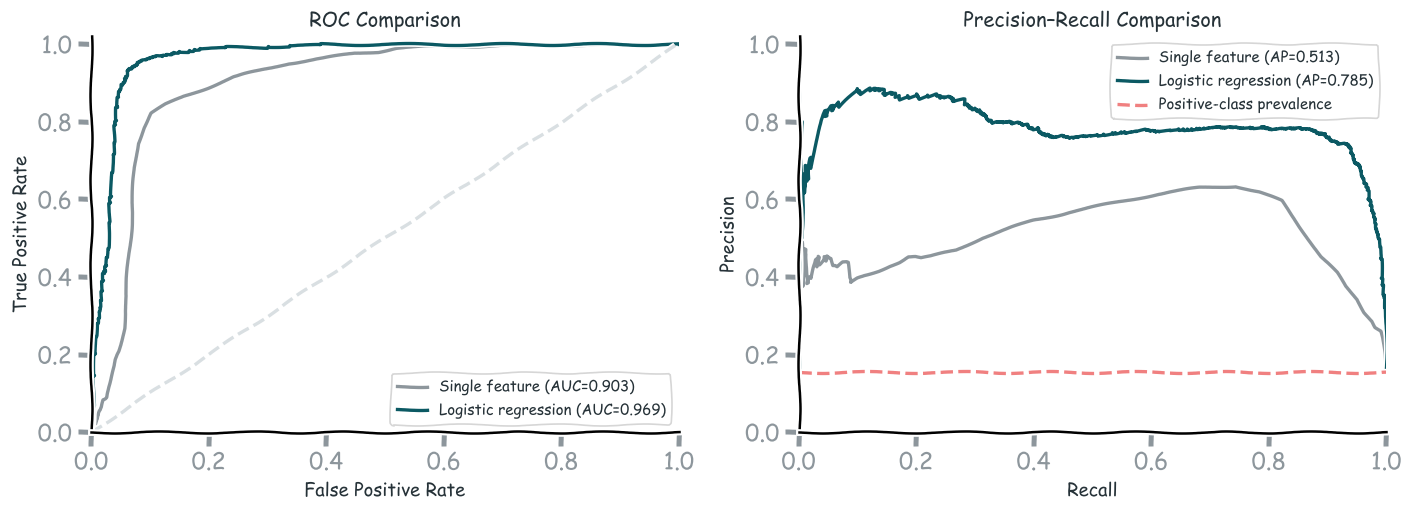

In [22]:

from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

width_idx = FEATURE_NAMES.index("QRS width proxy (ms)")

mean_normal = X_train[y_train == 0, width_idx].mean()
mean_pvc = X_train[y_train == 1, width_idx].mean()

direction = 1.0 if mean_pvc >= mean_normal else -1.0

baseline_val = direction * X_val[:, width_idx]
logistic_val = p_val

auc_baseline = roc_auc_score(y_val, baseline_val)
auc_logistic = roc_auc_score(y_val, logistic_val)

ap_baseline = average_precision_score(
    y_val, baseline_val
)
ap_logistic = average_precision_score(
    y_val, logistic_val
)

# ROC curves
fpr_base, tpr_base, _ = roc_curve(
    y_val, baseline_val
)

fpr_log, tpr_log, _ = roc_curve(
    y_val, logistic_val
)

# Precision-recall curves
prec_base, rec_base, _ = precision_recall_curve(
    y_val, baseline_val
)

prec_log, rec_log, _ = precision_recall_curve(
    y_val, logistic_val
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ROC
axes[0].plot(
    fpr_base, tpr_base,
    color=GRAY, lw=2,
    label=f"Single feature (AUC={auc_baseline:.3f})"
)

axes[0].plot(
    fpr_log, tpr_log,
    color=TEAL, lw=2,
    label=f"Logistic regression (AUC={auc_logistic:.3f})"
)

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--", color=LIGHT_GRAY
)

axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Comparison")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.15)

# Precision-recall
axes[1].plot(
    rec_base, prec_base,
    color=GRAY, lw=2,
    label=f"Single feature (AP={ap_baseline:.3f})"
)

axes[1].plot(
    rec_log, prec_log,
    color=TEAL, lw=2,
    label=f"Logistic regression (AP={ap_logistic:.3f})"
)

axes[1].axhline(
    np.mean(y_val),
    color=RED, linestyle="--",
    label="Positive-class prevalence"
)

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall Comparison")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.15)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

plt.tight_layout()
plt.show()

#### Threshold Selection

Training logistic regression produces a scoring model.
We still need to decide how to convert its scores into class predictions.

Suppose we want to maximize detection probability subject to a false-positive-rate requirement:
$$
\max_{\tau}\;TPR(\tau)
$$
subject to
$$
FPR(\tau)\leq\alpha.
$$
This resembles the Neyman–Pearson criterion introduced in Experiment 1.
However, an important distinction exists.
In Experiment 1, we obtained a theoretical threshold using known Gaussian distributions.
Here, the score distributions are not known analytically.
Therefore, we select the threshold empirically using validation data.

In this experiment, we require
$$
\alpha=0.10.
$$
We will identify a validation threshold satisfying this requirement while maximizing validation recall.

**Note:** 
>The chosen threshold only guarantees the empirical validation operating point. It does not guarantee that the same FPR will be achieved on new recordings.
This is precisely why we need an independent test set.

In [23]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

# Choose threshold using validation data
MAX_FPR = 0.10

fpr_val, tpr_val, thresholds_val = roc_curve(
    y_val, p_val
)

eligible = np.flatnonzero(
    (fpr_val <= MAX_FPR + 1e-12)
    & np.isfinite(thresholds_val)
)

if len(eligible) == 0:
    raise RuntimeError(
        "No finite threshold satisfies the FPR requirement."
    )

best_point = eligible[np.argmax(tpr_val[eligible])]

ecg_threshold = float(thresholds_val[best_point])

print(f"Selected threshold: {ecg_threshold:.4f}")
print(f"Validation FPR: {fpr_val[best_point]:.4f}")
print(f"Validation TPR: {tpr_val[best_point]:.4f}")

# Final test evaluation
p_test = ecg_model.predict_proba(X_test)[:, 1]

y_pred_default = (p_test > 0.5).astype(int)
y_pred_selected = (p_test >= ecg_threshold).astype(int)

def report_metrics(y_true, y_pred, title):
    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn)
    tpr = tp / (tp + fn)

    print(f"\n{title}")
    print("-" * 45)
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"FPR:       {fpr:.4f}")
    print(f"TPR:       {tpr:.4f}")
    print("Confusion matrix:")
    print(cm)

report_metrics(
    y_test, y_pred_default,
    "Test performance — threshold 0.5"
)

report_metrics(
    y_test, y_pred_selected,
    "Test performance — validation-selected threshold"
)

# Threshold-independent metrics
print("\nTest score metrics")
print("-" * 45)
print(f"ROC-AUC: {roc_auc_score(y_test, p_test):.4f}")
print(f"AP:      {average_precision_score(y_test, p_test):.4f}")
print(f"Log loss: {log_loss(y_test, p_test):.4f}")

# Always-normal accuracy for context
majority_accuracy = np.mean(y_test == 0)

print(f"Always-normal accuracy: {majority_accuracy:.4f}")

Selected threshold: 0.6724
Validation FPR: 0.0992
Validation TPR: 0.9631

Test performance — threshold 0.5
---------------------------------------------
Accuracy:  0.9968
Precision: 0.9929
Recall:    0.9973
FPR:       0.0034
TPR:       0.9973
Confusion matrix:
[[3801   13]
 [   5 1817]]

Test performance — validation-selected threshold
---------------------------------------------
Accuracy:  0.9972
Precision: 0.9945
Recall:    0.9967
FPR:       0.0026
TPR:       0.9967
Confusion matrix:
[[3804   10]
 [   6 1816]]

Test score metrics
---------------------------------------------
ROC-AUC: 0.9984
AP:      0.9931
Log loss: 0.1116
Always-normal accuracy: 0.6767


#### Visualizing Classification Decisions: Confusion Matrix

A confusion matrix summarizes the relationship between the true class labels and the classifier's predictions.
For binary classification, it contains four quantities:
$$
\mathbf C=
\begin{bmatrix}
TN & FP\\
FN & TP
\end{bmatrix}.
$$
Here:
- **True Negative (TN):** A normal beat correctly classified as normal.
- **False Positive (FP):** A normal beat incorrectly classified as PVC.
- **False Negative (FN):** A PVC incorrectly classified as normal.
- **True Positive (TP):** A PVC correctly classified as PVC.

The diagonal entries represent correct predictions, while the off-diagonal entries represent classification errors.
We will compare the confusion matrices obtained using:
1. The default probability threshold, $\tau=0.5$.
2. The threshold selected using validation data.

To facilitate interpretation, each cell displays the number of observations corresponding to a particular combination of true and predicted classes.

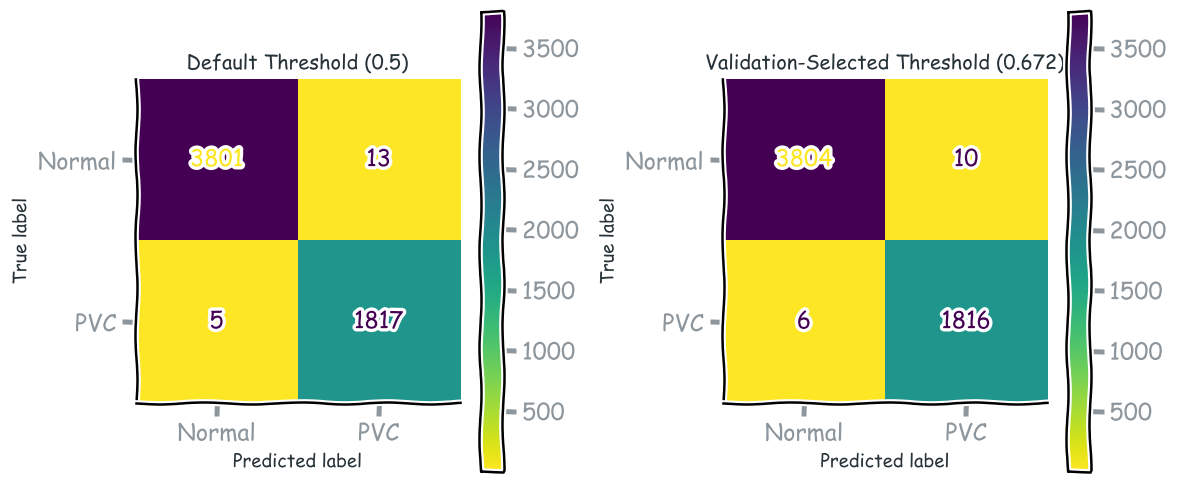

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
from matplotlib.colors import LinearSegmentedColormap

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Default threshold
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_default,
    labels=[0, 1],
    display_labels=["Normal", "PVC"],
    cmap="viridis_r",
    values_format="d",
    ax=axes[0]
)

axes[0].set_title("Default Threshold (0.5)")

# Validation-selected threshold
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_selected,
    labels=[0, 1],
    display_labels=["Normal", "PVC"],
    cmap="viridis_r",
    values_format="d",
    ax=axes[1]
)

axes[1].set_title(
    f"Validation-Selected Threshold ({ecg_threshold:.3f})"
)

plt.tight_layout()
plt.show()

We have now evaluated the ECG classifier using a recording-separated test set.
Several important lessons follow.

**1. Learning a classifier does not determine its operating threshold.**

Logistic regression produces continuous scores.
Changing the threshold affects precision, recall, false alarms, and the confusion matrix.

**2. Validation is part of model selection.**

We used validation data to select:
- The inverse regularization strength `C`.
- The operational decision threshold.

Neither was selected using test data.

**3. ROC-AUC does not determine performance at one threshold.**

A classifier can provide useful ranking performance but still perform poorly at a particular operating point.

**4. Accuracy alone can be misleading.**

If most observations belong to the normal class, predicting "normal" for every observation may produce deceptively high accuracy.

This is why we also report precision, recall, ROC-AUC, and average precision.

**5. Generalization depends on the evaluation setting.**

Our test recordings are different from those used to fit and validate the model.

Performance may therefore differ from training or validation performance because of changes in patient characteristics, signal morphology, class prevalence, or recording conditions.

**Note:**>A classification result is meaningful only when we understand the scoring model, threshold, dataset, and evaluation procedure that produced it.

*We will investigate these issues more systematically in Experiment 4.*

#### Optional: Does the Classifier Perform Equally Well Across Recordings?

The recording-level analysis reveals substantial differences in classification performance, even though the same trained model and decision threshold are used for every recording.
In particular, Recording 203 exhibits a noticeably higher false-positive rate than the other recordings.
This highlights an important distinction between aggregate performance and recording-level generalization.
The threshold was selected to satisfy an overall validation false-positive-rate requirement:
$$
FPR_{\mathrm{val}}\leq 0.10.
$$
However, satisfying this constraint across the complete validation set does not guarantee that it will hold for every individual recording.
The classifier also performs exceptionally well on the two selected test recordings. This indicates strong discrimination on those recordings, but it does not establish equally strong performance across all possible patients or recording conditions.
Differences in signal morphology, measurement conditions, and feature distributions may affect how well a model generalizes.

**Note:**
>A single aggregate metric may conceal substantial performance differences across data groups. Strong performance on a small held-out test set does not guarantee equally strong performance across a broader population. Classification thresholds selected using one set of recordings may produce different operating characteristics on other recordings. Generalization should be evaluated in relation to the intended deployment setting, not simply through a random selection of observations.

In [27]:
print("Recording-level classification performance")
print("-" * 90)

print(
    f"{'Split':<12}"
    f"{'Record':<10}"
    f"{'Beats':>8}"
    f"{'PVC %':>9}"
    f"{'AUC':>9}"
    f"{'AP':>9}"
    f"{'FPR':>9}"
    f"{'Recall':>9}"
)

for split_name, X_part, y_part, groups_part in [
    ("Validation", X_val, y_val, groups_val),
    ("Test", X_test, y_test, groups_test)
]:

    probabilities = ecg_model.predict_proba(X_part)[:, 1]

    for rid in np.unique(groups_part):

        mask = groups_part == rid

        yt = y_part[mask]
        pt = probabilities[mask]

        predictions = (pt >= ecg_threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            yt, predictions, labels=[0, 1]
        ).ravel()

        auc = roc_auc_score(yt, pt)
        ap = average_precision_score(yt, pt)

        fpr = fp / (fp + tn)
        recall = tp / (tp + fn)

        print(
            f"{split_name:<12}"
            f"{rid:<10}"
            f"{len(yt):>8d}"
            f"{100*np.mean(yt):>8.1f}%"
            f"{auc:>9.4f}"
            f"{ap:>9.4f}"
            f"{fpr:>9.4f}"
            f"{recall:>9.4f}"
        )

Recording-level classification performance
------------------------------------------------------------------------------------------
Split       Record       Beats    PVC %      AUC       AP      FPR   Recall
Validation  203           2972    14.9%   0.9512   0.7620   0.1788   0.9347
Validation  221           2426    16.3%   1.0000   1.0000   0.0000   0.9949
Test        208           2577    38.5%   0.9981   0.9844   0.0032   0.9960
Test        233           3059    27.1%   0.9996   0.9989   0.0022   0.9976


### 2.5 Optional: Mathematical Foundations of Logistic Regression

Logistic regression is a discriminative probabilistic model.
It directly models the conditional probability of a class label given the features:
$$
P(Y=1|\mathbf x).
$$

#### From Linear Scores to Probabilities


Suppose we construct a linear score
$$
z=\mathbf w^T\mathbf x+b.
$$
Unlike a probability, $z$ can take any real value.

We transform it using the sigmoid function:
$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$
This gives
$$
p_i=\sigma(\mathbf w^T\mathbf x_i+b).
$$
Equivalently, logistic regression assumes that the log odds are linear:
$$
\boxed{
\log\frac{p_i}{1-p_i}=
\mathbf w^T\mathbf x_i+b.
}
$$

#### Bernoulli Likelihood

For binary labels $y_i\in\{0,1\}$, the conditional probability of each observation is
$$
P(y_i|\mathbf x_i)=
p_i^{y_i}(1-p_i)^{1-y_i}.
$$
Assuming independent labeled observations under the model, the likelihood of the dataset is
$$
L(\mathbf w,b)=
\prod_{i=1}^{M}
p_i^{y_i}(1-p_i)^{1-y_i}.
$$
Taking the negative logarithm gives
$$
-\log L(\mathbf w,b)=
-\sum_{i=1}^{M}
\left[
y_i\log p_i+
(1-y_i)\log(1-p_i)
\right].
$$
Dividing by $M$ gives the average binary cross-entropy loss.

#### Regularization

To discourage excessively large coefficients, we can add an $L_2$ penalty:
$$
\boxed{
\min_{\mathbf w,b}
\left[
-\frac{1}{M}
\sum_{i=1}^{M}
\left(
y_i\log p_i+
(1-y_i)\log(1-p_i)
\right)+
\lambda\|\mathbf w\|_2^2
\right].
}
$$
Here, $\lambda$ controls regularization strength.
The exact scaling convention differs between mathematical formulations and software implementations.

In scikit-learn, `C` is an inverse regularization parameter.

#### Connection to Ridge Regression

The structure is similar to ridge regression:
$$
\text{Data-fit loss}+
\text{Regularization penalty}.
$$
The main difference lies in the data-fit loss.
- Ridge regression typically uses squared error.
- Logistic regression uses binary cross-entropy.

This illustrates the general principle of empirical risk minimization that appears throughout the course.

### 2.6 Optional: Probability Calibration

A classifier may distinguish positive and negative examples well without producing reliable probability estimates.
For example, consider all observations assigned a predicted probability near $0.8$.
If the model is well calibrated, approximately 80% of those observations should belong to the positive class.

A reliability diagram compares:
- The mean predicted probability within each probability bin.
- The observed fraction of positive examples within that bin.

A perfectly calibrated model would lie along the diagonal line
$$
\text{Observed frequency}=
\text{Predicted probability}.
$$

#### Discrimination vs. Calibration

These are different properties.

**Discrimination** measures the ability to rank positive observations above negative observations.

**Calibration** measures how closely predicted probabilities correspond to observed frequencies.

A model may achieve strong ROC-AUC while being poorly calibrated.
This distinction is particularly relevant when predictions will be used in decision-making systems.

** Why Can Calibration Change?**

Calibration can be affected by:
- Model misspecification.
- Regularization.
- Differences between training and deployment populations.
- Changes in positive-class prevalence.
- Distribution shifts between recordings.

Our ECG training and test sets contain different recordings, so probability calibration may differ between them.

In the following  diagnostic, we evaluate the probability calibration of the selected model on the held-out test set.

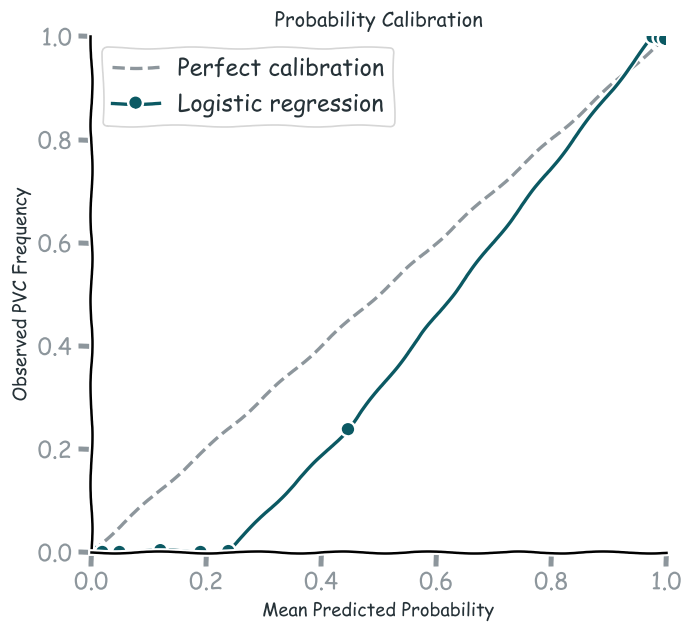

Test Brier score: 0.0208
Test PVC prevalence: 0.3233


In [24]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Calibration on held-out test data
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    p_test,
    n_bins=10,
    strategy="quantile"
)

brier = brier_score_loss(y_test, p_test)

fig, ax = plt.subplots(figsize=(6, 5.5))

ax.plot(
    [0, 1], [0, 1],
    color=GRAY,
    linestyle="--",
    label="Perfect calibration"
)

ax.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    color=TEAL,
    lw=2,
    label="Logistic regression"
)

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed PVC Frequency")
ax.set_title("Probability Calibration")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.15)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Test Brier score: {brier:.4f}")
print(f"Test PVC prevalence: {np.mean(y_test):.4f}")

### Experiment 2: Summary

In this experiment, we studied supervised classification using real ECG recordings.
The main lessons are:

**1. Signal representation matters.**  
We transformed raw ECG segments into interpretable feature vectors describing beat morphology and timing.

**2. Classification models learn from labeled examples.**  
Logistic regression learned a conditional scoring rule without requiring explicitly specified class-conditional feature distributions.

**3. Training and prediction are separate operations.**  
The model learned parameters from the training data, while its scores were converted to class labels using a decision threshold.

**4. Evaluation metrics answer different questions.**  
- ROC-AUC describes ranking performance.
- Precision and recall describe the quality of positive decisions at particular operating points.
- Average precision summarizes precision–recall performance.

**5. Model selection must respect data splitting.**  
We selected regularization strength and the decision threshold using validation data.
The test recordings were reserved for evaluating the finalized model.

**6. Generalization must be interpreted in context.**  
Performance on new beats from familiar recordings is not necessarily equivalent to performance on entirely unseen recordings or patients.

# Part III: Regression & Regularization

## Experiment 3: Can a Simpler Model Generalize Better?

We now consider another fundamental supervised learning problem: **regression**.
Instead of predicting a class label, we want to predict a continuous quantity from observed input features.
In many engineering applications, the relationship between an input and an output is nonlinear and must be inferred from noisy measurements.

Examples include:
- Predicting a sensor output from an applied physical input.
- Estimating the response of an unknown dynamical system.
- Predicting communication-channel characteristics from measured features.
- Modeling the relationship between operating conditions and measurement errors.

In this experiment, we will investigate how the complexity of a regression model affects its ability to learn a nonlinear relationship.

### 3.1 Problem Formulation

Consider a measurement system whose output depends on an input variable $x$.
The observed output is
$$
\boxed{
y_i=f(x_i)+\epsilon_i,
}
$$
where:
- $x_i$: Input to the system.
- $y_i$: Observed output.
- $f(x)$: Unknown nonlinear input-output relationship.
- $\epsilon_i$: Measurement noise.

We assume independent Gaussian noise:
$$
\epsilon_i\sim\mathcal N(0,\sigma^2).
$$
Our objective is to learn a predictive model
$$
\hat y=\hat f(x)
$$
from a limited number of noisy observations.

#### A Controlled Simulation

To investigate the behavior of different regression methods, we will generate synthetic measurements.
The underlying relationship will be:
$$
f(x) =
0.65\sin(2\pi x)+0.45x+0.25x^2.
$$
The model will not be given this function.
It will only receive input-output observations:
$$
\mathcal D_{\mathrm{train}}=
\{(x_i,y_i)\}_{i=1}^{M}.
$$
Because this is a simulation, we know the actual underlying function and can use it to evaluate how accurately the learned models recover the relationship.

*The true function is available to us as experiment designers, but it is not available to the learning algorithms.*

> **Q:** If we increase the flexibility of our regression model, will it always produce more accurate predictions on unseen observations?

#### Generate the Regression Dataset

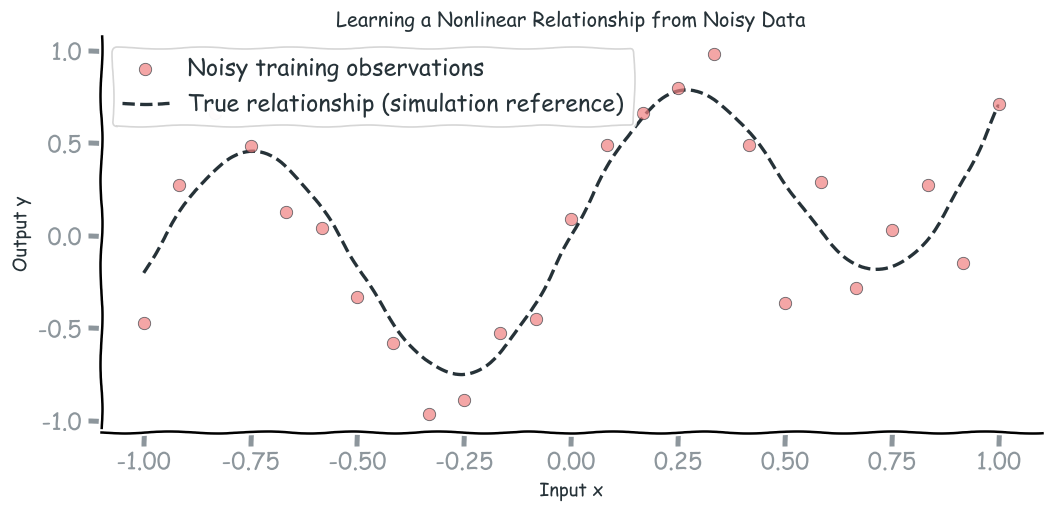

Training samples: 25
Validation samples: 200
Test samples: 220
Noise standard deviation: 0.3


In [83]:
rng_reg = np.random.default_rng(BASE_SEED + 301)

# Underlying nonlinear relationship
def true_function(x):
    x = np.asarray(x).reshape(-1)

    return (
        0.65 * np.sin(2 * np.pi * x)
        + 0.45 * x
        + 0.25 * x**2
    )


# Dataset parameters
n_train = 25
n_val = 200
n_test = 220

noise_std = 0.30

# Input observations
x_train_reg = np.linspace(-1, 1, n_train)

x_val_reg = rng_reg.uniform(-1, 1, n_val)
x_test_reg = rng_reg.uniform(-1, 1, n_test)

# Noisy measurements
y_train_reg = (
    true_function(x_train_reg)
    + noise_std * rng_reg.standard_normal(n_train)
)

y_val_reg = (
    true_function(x_val_reg)
    + noise_std * rng_reg.standard_normal(n_val)
)

y_test_reg = (
    true_function(x_test_reg)
    + noise_std * rng_reg.standard_normal(n_test)
)

# scikit-learn expects 2D feature matrices
X_train_reg = x_train_reg.reshape(-1, 1)
X_val_reg = x_val_reg.reshape(-1, 1)
X_test_reg = x_test_reg.reshape(-1, 1)

# Dense input grid for visualization
x_grid = np.linspace(-1, 1, 500)
X_grid = x_grid.reshape(-1, 1)

y_true_grid = true_function(x_grid)

# Visualization
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.scatter(
    x_train_reg,
    y_train_reg,
    color=RED,
    alpha=0.7,
    s=55,
    edgecolor=DARK,
    linewidth=0.5,
    label="Noisy training observations",
    zorder=3
)

ax.plot(
    x_grid,
    y_true_grid,
    color=DARK,
    linestyle="--",
    lw=2,
    label="True relationship (simulation reference)"
)

ax.set_xlabel("Input x")
ax.set_ylabel("Output y")

ax.set_title(
    "Learning a Nonlinear Relationship from Noisy Data"
)

ax.legend()
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

print(f"Training samples: {n_train}")
print(f"Validation samples: {n_val}")
print(f"Test samples: {n_test}")
print(f"Noise standard deviation: {noise_std}")

### 3.2 Polynomial Regression and Model Complexity

A basic linear regression model has the form
$$
\hat y=\beta_0+\beta_1x.
$$
This model can only represent a straight line.
However, many relationships between physical quantities are nonlinear.
One approach is to expand the input into a set of nonlinear basis functions.
For polynomial regression of degree $p$,
$$
\boxed{
\hat y =
\beta_0+\beta_1x+\beta_2x^2+\cdots+\beta_px^p.
}
$$
We define the feature mapping
$$
\boldsymbol\phi(x) =
\begin{bmatrix}
1 & x & x^2 & \cdots & x^p
\end{bmatrix}^{T}.
$$
The model becomes
$$
\hat y=\boldsymbol\phi(x)^T\boldsymbol\beta.
$$

***Why Is This Still Linear Regression?***

Although the prediction is nonlinear in $x$, it remains linear in the model parameters $\boldsymbol\beta$.
This distinction is important:  
- *Linear regression means linearity in the parameters, not necessarily linearity in the original input variables.*

#### Model Complexity

Increasing the polynomial degree adds more basis functions and increases the flexibility of the model.

For example:
- Degree 1: Straight line.
- Degree 3: Cubic polynomial.
- Degree 5: More flexible nonlinear relationship.
- Degree 12: Highly flexible polynomial.

Higher flexibility allows the model to represent more complicated patterns.
However, it also allows the model to fit random fluctuations in the training observations.
This creates the possibility of **overfitting**.

#### Implementation

We will use `PolynomialFeatures` from scikit-learn to construct the expanded feature matrix.
The features will then be standardized using `StandardScaler`.
Finally, `LinearRegression` will estimate the regression coefficients.
The entire sequence will be implemented as a pipeline.
This ensures that preprocessing parameters are estimated from training data only.

> **Q3:** Does More Complexity Always Help?  
> Suppose we increase the polynomial degree from 1 to 12. As the model becomes more flexible, its training error decreases.  
> 1. Does a lower training error guarantee better predictions on unseen data?
> 2. Can a model become too flexible?
> 3. How should we determine the appropriate polynomial degree?  
> We will investigate these questions by fitting polynomial models of different complexities to the same noisy observations.

#### Models of Different Complexities

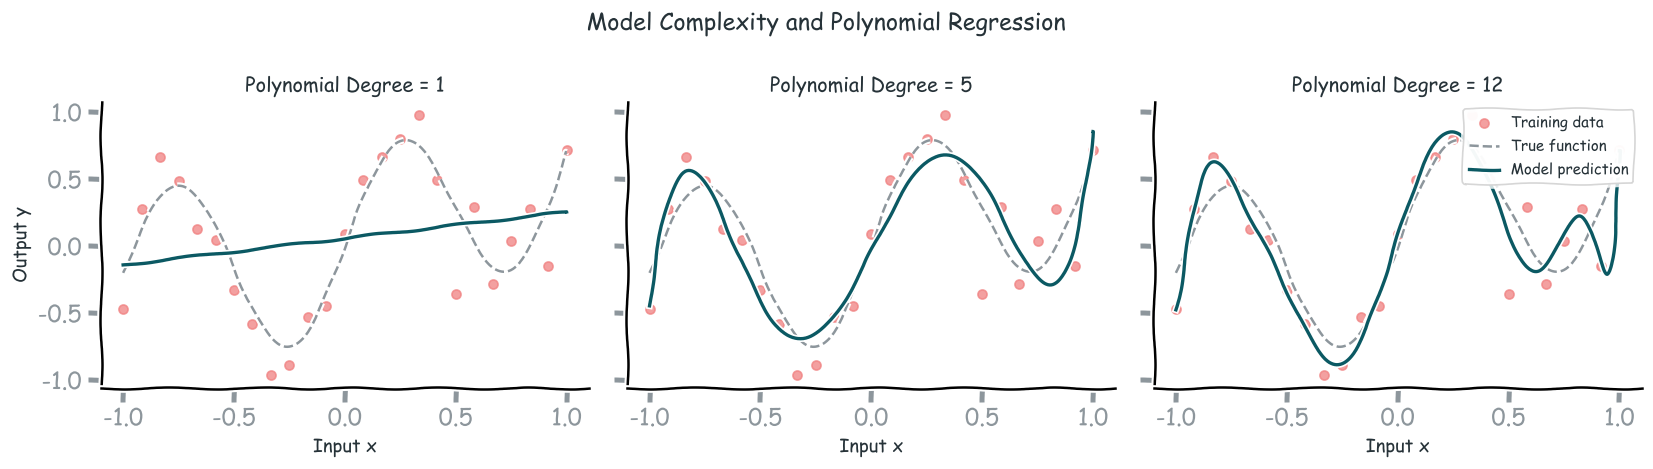

In [84]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error


# Polynomial regression pipeline
def make_polynomial_model(degree, estimator):
    return make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False
        ),
        StandardScaler(),
        estimator
    )


# Models with different complexities
degrees_demo = [1, 5, 12]

degree_models = {}

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4),
    sharex=True,
    sharey=True
)

for ax, degree in zip(axes, degrees_demo):

    model = make_polynomial_model(
        degree,
        LinearRegression()
    )

    model.fit(X_train_reg, y_train_reg)

    degree_models[degree] = model

    y_pred_grid = model.predict(X_grid)

    ax.scatter(
        x_train_reg,
        y_train_reg,
        color=RED,
        s=30,
        alpha=0.75,
        label="Training data"
    )

    ax.plot(
        x_grid,
        y_true_grid,
        color=GRAY,
        linestyle="--",
        lw=1.5,
        label="True function"
    )

    ax.plot(
        x_grid,
        y_pred_grid,
        color=TEAL,
        lw=2,
        label="Model prediction"
    )

    ax.set_title(f"Polynomial Degree = {degree}")
    ax.set_xlabel("Input x")

axes[0].set_ylabel("Output y")

axes[-1].legend(
    loc="upper right",
    fontsize=9
)

plt.suptitle(
    "Model Complexity and Polynomial Regression",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 3.3 Training Error, Validation Error, and Overfitting

**Why Can Better Training Fits Produce Worse Predictions?**   
Recall that least-squares regression estimates model parameters by minimizing the sum of squared residuals.
For a polynomial feature matrix $\mathbf\Phi$, the regression model is
$$
\mathbf y=\mathbf\Phi\boldsymbol\beta+\boldsymbol\epsilon.
$$
Ordinary least squares solves
$$
\boxed{
\hat{\boldsymbol\beta}_{LS}=
\arg\min_{\boldsymbol\beta}
\|\mathbf y-\mathbf\Phi\boldsymbol\beta\|_2^2.
}
$$
This objective only measures the fit to the training observations.
It does not directly measure how well the model will predict unseen observations.

#### Empirical Risk

For squared-error regression, the empirical training risk is
$$
\hat R_{\mathrm{train}}(f)=
\frac{1}{M}
\sum_{i=1}^{M}
(y_i-f(x_i))^2.
$$
We can estimate prediction performance using an independent validation set:
$$
\hat R_{\mathrm{val}}(f)=
\frac{1}{M_{\mathrm{val}}}
\sum_{i=1}^{M_{\mathrm{val}}}
(y_i-f(x_i))^2.
$$

#### Underfitting

A model underfits when it is too restrictive to capture the relevant structure in the data.  
For example, a straight line may be insufficient for a strongly nonlinear relationship.

#### Overfitting

A model overfits when it adapts too strongly to the particular observations used for training, including their noise.  
An overfitted model may achieve very low training error but perform poorly on new observations.

#### Model Selection

We will compare polynomial models using:
- Training mean squared error (MSE).
- Validation mean squared error (MSE).

The validation set will be used to select model complexity.
The independent test set will remain unused until we have finalized our model-selection procedure.

#### Model Complexity Experiment

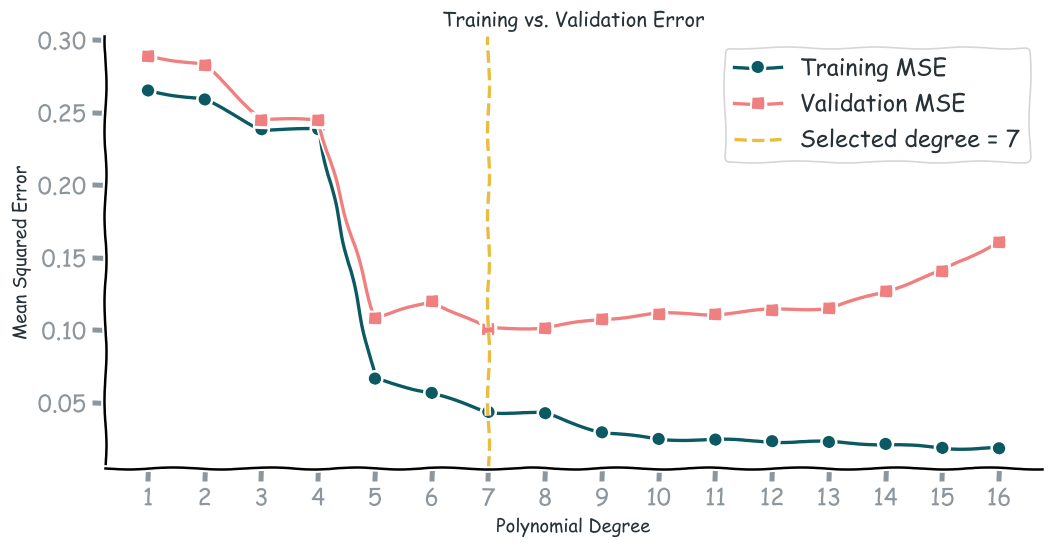

Best polynomial degree: 7
Training MSE: 0.04359
Validation MSE: 0.10114


In [85]:
POLY_DEGREES = np.arange(1, 17)

ols_models = {}

ols_train_mse = []
ols_val_mse = []

for degree in POLY_DEGREES:

    model = make_polynomial_model(
        degree,
        LinearRegression()
    )

    model.fit(X_train_reg, y_train_reg)

    ols_models[degree] = model

    train_pred = model.predict(X_train_reg)
    val_pred = model.predict(X_val_reg)

    ols_train_mse.append(
        mean_squared_error(y_train_reg, train_pred)
    )

    ols_val_mse.append(
        mean_squared_error(y_val_reg, val_pred)
    )

ols_train_mse = np.asarray(ols_train_mse)
ols_val_mse = np.asarray(ols_val_mse)

# Best degree according to validation MSE
best_ols_idx = np.argmin(ols_val_mse)

best_ols_degree = int(POLY_DEGREES[best_ols_idx])
best_ols_model = ols_models[best_ols_degree]

# Visualization
fig, ax = plt.subplots(figsize=(9, 4.8))

ax.plot(
    POLY_DEGREES,
    ols_train_mse,
    marker="o",
    color=TEAL,
    lw=2,
    label="Training MSE"
)

ax.plot(
    POLY_DEGREES,
    ols_val_mse,
    marker="s",
    color=RED,
    lw=2,
    label="Validation MSE"
)

ax.axvline(
    best_ols_degree,
    color=YELLOW,
    linestyle="--",
    lw=2,
    label=f"Selected degree = {best_ols_degree}"
)

ax.set_xlabel("Polynomial Degree")
ax.set_ylabel("Mean Squared Error")

ax.set_title(
    "Training vs. Validation Error"
)

ax.set_xticks(POLY_DEGREES)

ax.legend()

plt.tight_layout()
plt.show()

print(f"Best polynomial degree: {best_ols_degree}")
print(f"Training MSE: {ols_train_mse[best_ols_idx]:.5f}")
print(f"Validation MSE: {ols_val_mse[best_ols_idx]:.5f}")

The experiment illustrates an important distinction.
As polynomial degree increases, the model becomes more flexible.
For nested polynomial models, increasing the degree cannot increase the minimum achievable training squared error when the optimization is solved exactly.
However, the validation error does not necessarily decrease.
This happens because the model may start fitting random variations that are specific to the training observations.

**The Bias–Variance Perspective**

Increasing model complexity can reduce systematic approximation error.
However, highly flexible models may also become sensitive to the particular training sample.
This is often described as a trade-off between bias and variance.
- **High bias:** The model is too restrictive and misses relevant structure.
- **High variance:** The fitted model changes substantially when the training observations change.


> A validation error curve is not guaranteed to have a perfectly U-shaped form for every dataset. Its shape depends on the data-generating process, sample size, noise level, and model family. The important lesson is that **training and generalization performance are different quantities**.

### 3.4 Regularization: Ridge and LASSO

#### Regularized Regression

Ordinary least squares minimizes training residual error.
When the model is highly flexible, this may result in large or unstable coefficient estimates.
Regularization modifies the training objective by introducing a penalty on the model parameters.
The general formulation is
$$
\boxed{
\hat{\boldsymbol\beta} =
\arg\min_{\boldsymbol\beta}
\left[
\mathcal L(\boldsymbol\beta)
+
\lambda\Omega(\boldsymbol\beta)
\right].
}
$$
Here:
- $\mathcal L$: Data-fitting loss.
- $\Omega$: Regularization penalty.
- $\lambda$: Regularization strength.

The goal is to balance fitting the training observations against imposing useful constraints on the solution.


#### Ridge Regression

Ridge regression uses an $L_2$ penalty:
$$
\boxed{
\hat{\boldsymbol\beta}_{Ridge}=
\arg\min_{\boldsymbol\beta}
\left[
\|\mathbf y-\mathbf\Phi\boldsymbol\beta\|_2^2+
\lambda\|\boldsymbol\beta\|_2^2
\right].
}
$$
The intercept is typically excluded from the penalty.
Ridge encourages smaller coefficients and can improve the stability of the regression solution.

#### LASSO

LASSO uses an $L_1$ penalty:
$$
\boxed{
\hat{\boldsymbol\beta}_{LASSO}=
\arg\min_{\boldsymbol\beta}
\left[
\frac{1}{2M}
\|\mathbf y-\mathbf\Phi\boldsymbol\beta\|_2^2+
\lambda\|\boldsymbol\beta\|_1
\right].
}
$$
The $L_1$ penalty can produce exactly zero coefficients.
Therefore, LASSO can perform a form of feature selection.

#### Ridge vs. LASSO

| Property | Ridge | LASSO |
|---|---|---|
| Penalty | $L_2$ | $L_1$ |
| Main effect | Coefficient shrinkage | Shrinkage and sparsity |
| Exact zero coefficients | Generally no | Possible |
| Highly correlated features | Often distributes weight among them | May select some over others |
| Optimization | Smooth objective | Nonsmooth at zero |

**Note:** Ridge and LASSO do not use the same scaling convention for their objectives in scikit-learn, so identical numerical values of `alpha` do not imply equivalent regularization strengths.

In our implementation, polynomial features are standardized before regularization.
This is important because regularization depends on the scale of the model coefficients.

#### Regularization experiment

We will use the same degree-12 polynomial feature representation for all three methods:

1. Ordinary least squares.
2. Ridge regression.
3. LASSO.

This allows us to investigate the effect of regularization while keeping the feature representation fixed.

In [86]:
REG_DEGREE = 12

RIDGE_ALPHAS = np.logspace(-5, 2, 18)
LASSO_ALPHAS = np.logspace(-3, -0.3, 16)

ridge_models = []
ridge_train_mse = []
ridge_val_mse = []

lasso_models = []
lasso_train_mse = []
lasso_val_mse = []

# Ridge
for alpha in RIDGE_ALPHAS:

    model = make_polynomial_model(
        REG_DEGREE,
        Ridge(alpha=alpha)
    )

    model.fit(X_train_reg, y_train_reg)

    ridge_models.append(model)

    ridge_train_mse.append(
        mean_squared_error(
            y_train_reg,
            model.predict(X_train_reg)
        )
    )

    ridge_val_mse.append(
        mean_squared_error(
            y_val_reg,
            model.predict(X_val_reg)
        )
    )

# LASSO
for alpha in LASSO_ALPHAS:

    model = make_polynomial_model(
        REG_DEGREE,
        Lasso(
            alpha=alpha,
            max_iter=60000,
            tol=1e-4
        )
    )

    model.fit(X_train_reg, y_train_reg)

    lasso_models.append(model)

    lasso_train_mse.append(
        mean_squared_error(
            y_train_reg,
            model.predict(X_train_reg)
        )
    )

    lasso_val_mse.append(
        mean_squared_error(
            y_val_reg,
            model.predict(X_val_reg)
        )
    )

ridge_train_mse = np.asarray(ridge_train_mse)
ridge_val_mse = np.asarray(ridge_val_mse)

lasso_train_mse = np.asarray(lasso_train_mse)
lasso_val_mse = np.asarray(lasso_val_mse)

# Select hyperparameters
best_ridge_idx = int(np.argmin(ridge_val_mse))
best_lasso_idx = int(np.argmin(lasso_val_mse))

best_ridge_alpha = RIDGE_ALPHAS[best_ridge_idx]
best_lasso_alpha = LASSO_ALPHAS[best_lasso_idx]

best_ridge_model = ridge_models[best_ridge_idx]
best_lasso_model = lasso_models[best_lasso_idx]

print("Selected regularization parameters")
print("-" * 45)

print(f"Ridge alpha: {best_ridge_alpha:.6g}")
print(f"Ridge validation MSE: {ridge_val_mse[best_ridge_idx]:.5f}")

print()

print(f"LASSO alpha: {best_lasso_alpha:.6g}")
print(f"LASSO validation MSE: {lasso_val_mse[best_lasso_idx]:.5f}")

Selected regularization parameters
---------------------------------------------
Ridge alpha: 0.000443669
Ridge validation MSE: 0.10341

LASSO alpha: 0.001
LASSO validation MSE: 0.10771


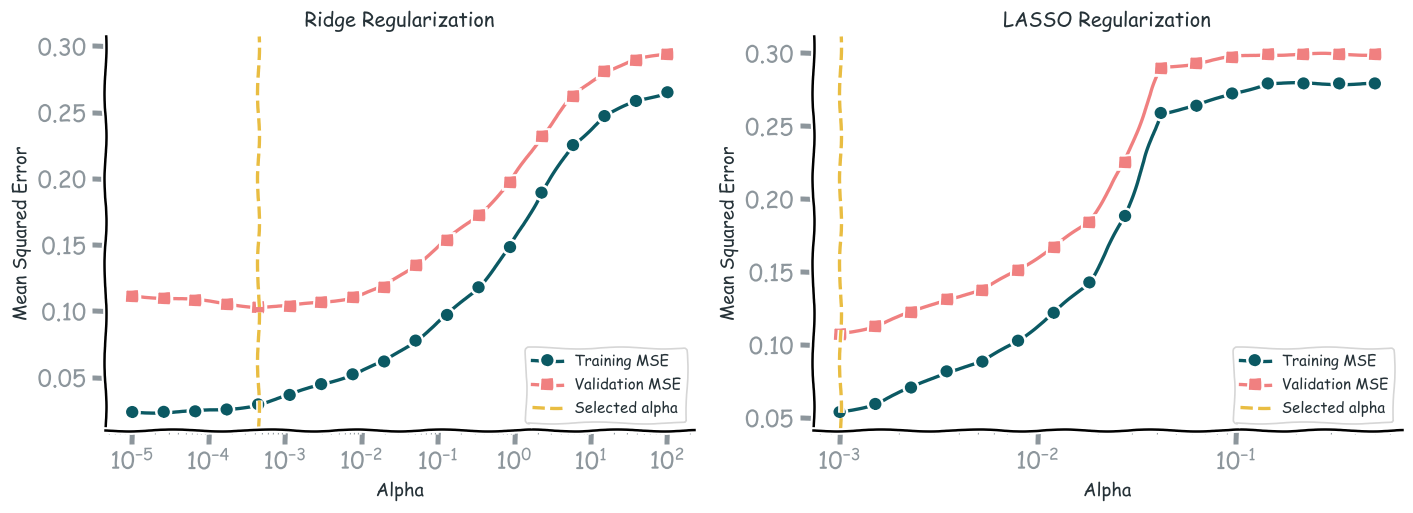

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Ridge
axes[0].semilogx(
    RIDGE_ALPHAS,
    ridge_train_mse,
    color=TEAL,
    marker="o",
    lw=2,
    label="Training MSE"
)

axes[0].semilogx(
    RIDGE_ALPHAS,
    ridge_val_mse,
    color=RED,
    marker="s",
    lw=2,
    label="Validation MSE"
)

axes[0].axvline(
    best_ridge_alpha,
    color=YELLOW,
    linestyle="--",
    lw=2,
    label="Selected alpha"
)

axes[0].set_title("Ridge Regularization")
axes[0].set_xlabel("Alpha")
axes[0].set_ylabel("Mean Squared Error")

# LASSO
axes[1].semilogx(
    LASSO_ALPHAS,
    lasso_train_mse,
    color=TEAL,
    marker="o",
    lw=2,
    label="Training MSE"
)

axes[1].semilogx(
    LASSO_ALPHAS,
    lasso_val_mse,
    color=RED,
    marker="s",
    lw=2,
    label="Validation MSE"
)

axes[1].axvline(
    best_lasso_alpha,
    color=YELLOW,
    linestyle="--",
    lw=2,
    label="Selected alpha"
)

axes[1].set_title("LASSO Regularization")
axes[1].set_xlabel("Alpha")
axes[1].set_ylabel("Mean Squared Error")

for ax in axes:
    ax.legend(fontsize=9)
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

#### Compare Models

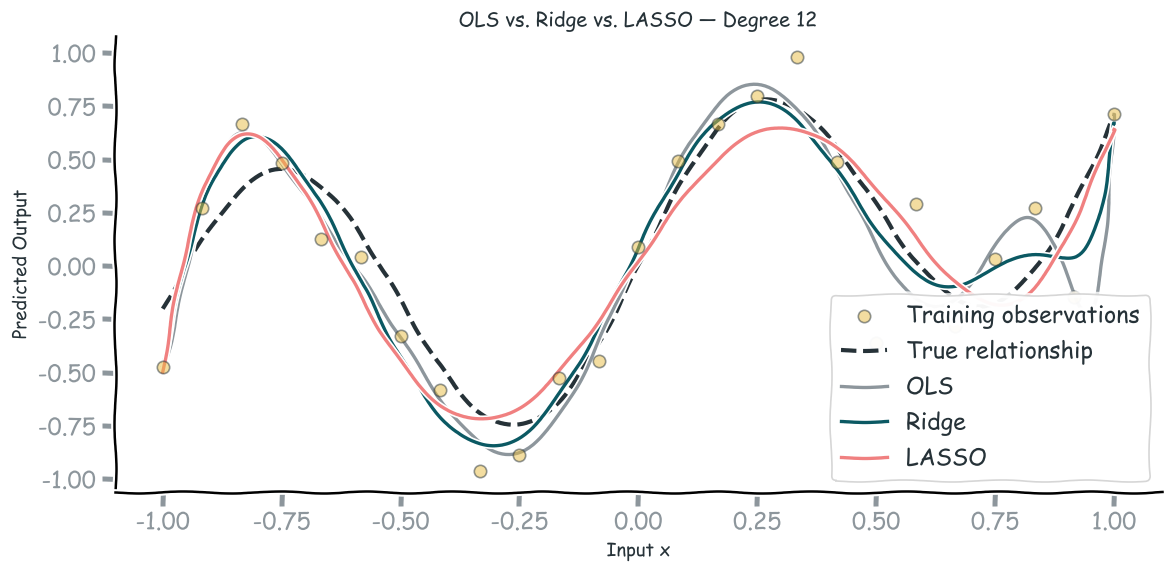

In [88]:
# Unregularized degree-12 polynomial
ols_12 = ols_models[REG_DEGREE]

models_compare = {
    "OLS": ols_12,
    "Ridge": best_ridge_model,
    "LASSO": best_lasso_model
}

colors_compare = {
    "OLS": GRAY,
    "Ridge": TEAL,
    "LASSO": RED
}

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    x_train_reg,
    y_train_reg,
    color=YELLOW,
    edgecolor=DARK,
    alpha=0.5,
    s=55,
    label="Training observations",
    zorder=5
)

ax.plot(
    x_grid,
    y_true_grid,
    color=DARK,
    linestyle="--",
    lw=2.5,
    label="True relationship"
)

for name, model in models_compare.items():

    ax.plot(
        x_grid,
        model.predict(X_grid),
        color=colors_compare[name],
        lw=2,
        label=name
    )

ax.set_xlabel("Input x")
ax.set_ylabel("Predicted Output")

ax.set_title(
    "OLS vs. Ridge vs. LASSO — Degree 12"
)

ax.legend()

plt.tight_layout()
plt.show()

#### Optional: Examine LASSO Sparsity

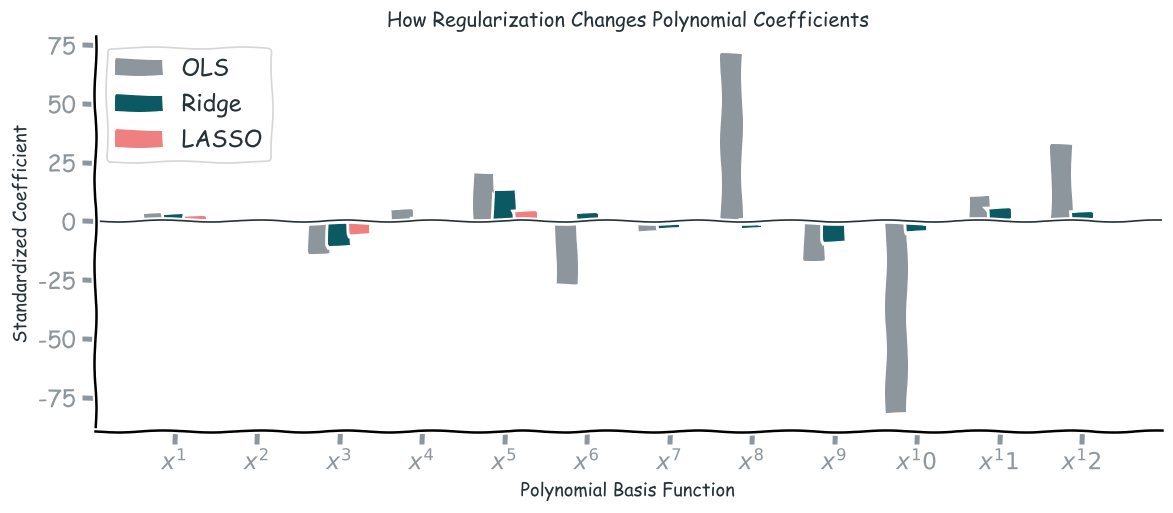

Nonzero LASSO coefficients: 8/12


In [89]:
coef_ols = ols_12.steps[-1][1].coef_
coef_ridge = best_ridge_model.steps[-1][1].coef_
coef_lasso = best_lasso_model.steps[-1][1].coef_

feature_indices = np.arange(1, REG_DEGREE + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))

width = 0.25

ax.bar(
    feature_indices - width,
    coef_ols,
    width=width,
    color=GRAY,
    label="OLS"
)

ax.bar(
    feature_indices,
    coef_ridge,
    width=width,
    color=TEAL,
    label="Ridge"
)

ax.bar(
    feature_indices + width,
    coef_lasso,
    width=width,
    color=RED,
    label="LASSO"
)

ax.axhline(0, color=DARK, lw=1)

ax.set_xticks(feature_indices)
ax.set_xticklabels(
    [rf"$x^{i}$" for i in feature_indices]
)

ax.set_xlabel("Polynomial Basis Function")
ax.set_ylabel("Standardized Coefficient")

ax.set_title(
    "How Regularization Changes Polynomial Coefficients"
)

ax.legend()

plt.tight_layout()
plt.show()

# Number of nonzero LASSO coefficients
n_nonzero = np.count_nonzero(
    np.abs(coef_lasso) > 1e-6
)

print(
    f"Nonzero LASSO coefficients: "
    f"{n_nonzero}/{REG_DEGREE}"
)

### 3.5 Model Selection and Final Evaluation

We have investigated three model families:
1. Ordinary polynomial regression.
2. Ridge-regularized polynomial regression.
3. LASSO-regularized polynomial regression.

For ordinary polynomial regression, we selected the polynomial degree using validation MSE.
For ridge and LASSO, we fixed the polynomial degree at 12 and selected regularization strength using validation MSE.
We can now compare the best validated candidate from each family.

**Why Not Select Using Training Error?**

Training error measures how closely a model fits the observations used during learning.
It does not necessarily reflect performance on unseen data.

**Why Not Select Using Test Error?**

The test set should provide an independent evaluation of the finalized model-selection procedure.
If we repeatedly inspect test results and modify the model accordingly, the test data become part of the development process.
This compromises the independence of the final evaluation.

**Our Procedure**

1. Fit candidate models using training data.
2. Select hyperparameters using validation data.
3. Compare the selected candidates using validation MSE.
4. Choose the final model.
5. Evaluate that model once on the held-out test set.

For simplicity, we will retain the selected model fitted on the original training set rather than refitting on the combined training and validation observations.
This keeps the experiment easy to interpret.

In [90]:
candidate_models = {
    f"OLS (degree={best_ols_degree})": best_ols_model,
    f"Ridge (degree={REG_DEGREE})": best_ridge_model,
    f"LASSO (degree={REG_DEGREE})": best_lasso_model
}

candidate_val_mse = {
    f"OLS (degree={best_ols_degree})":
        ols_val_mse[best_ols_idx],

    f"Ridge (degree={REG_DEGREE})":
        ridge_val_mse[best_ridge_idx],

    f"LASSO (degree={REG_DEGREE})":
        lasso_val_mse[best_lasso_idx]
}

# Select using validation performance
best_model_name = min(
    candidate_val_mse,
    key=candidate_val_mse.get
)

final_reg_model = candidate_models[best_model_name]

print("Validation model comparison")
print("-" * 50)

for name, mse in candidate_val_mse.items():
    print(f"{name:<25s} MSE={mse:.5f}")

print(f"\nSelected model: {best_model_name}")

# Independent test evaluation
y_test_pred = final_reg_model.predict(X_test_reg)

test_mse = mean_squared_error(
    y_test_reg,
    y_test_pred
)

test_rmse = np.sqrt(test_mse)

# Simple baseline: predict training mean
baseline_prediction = np.full_like(
    y_test_reg,
    y_train_reg.mean()
)

baseline_mse = mean_squared_error(
    y_test_reg,
    baseline_prediction
)

print("\nFinal test evaluation")
print("-" * 50)

print(f"Test MSE:  {test_mse:.5f}")
print(f"Test RMSE: {test_rmse:.5f}")
print(f"Baseline test MSE: {baseline_mse:.5f}")

Validation model comparison
--------------------------------------------------
OLS (degree=7)            MSE=0.10114
Ridge (degree=12)         MSE=0.10341
LASSO (degree=12)         MSE=0.10771

Selected model: OLS (degree=7)

Final test evaluation
--------------------------------------------------
Test MSE:  0.10535
Test RMSE: 0.32458
Baseline test MSE: 0.28473


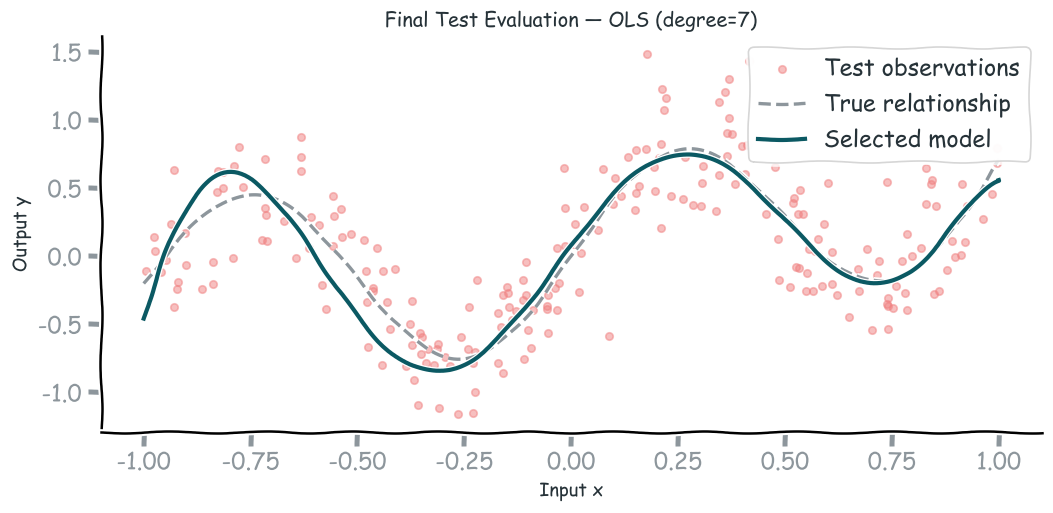

In [91]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.scatter(
    x_test_reg,
    y_test_reg,
    color=RED,
    s=20,
    alpha=0.5,
    label="Test observations"
)

ax.plot(
    x_grid,
    y_true_grid,
    color=GRAY,
    linestyle="--",
    lw=2,
    label="True relationship"
)

ax.plot(
    x_grid,
    final_reg_model.predict(X_grid),
    color=TEAL,
    lw=2.5,
    label="Selected model"
)

ax.set_xlabel("Input x")
ax.set_ylabel("Output y")

ax.set_title(
    f"Final Test Evaluation — {best_model_name}"
)

ax.legend()

plt.tight_layout()
plt.show()

The experiment illustrates why training performance alone is insufficient for model selection.
A more flexible model can achieve lower training error while performing worse on validation data.
Regularization can improve generalization by reducing the sensitivity of fitted coefficients to noisy observations.
However, regularization is not always necessary.
A model with fewer basis functions may generalize better than a heavily regularized high-degree model.


### 3.6 Optional: The Bias–Variance Trade-off

One of the central concepts in machine learning is the bias–variance trade-off.  
Suppose we repeatedly collect training datasets from the same underlying system.
Each dataset contains different noise realizations.
Consequently, the fitted model changes from one dataset to another.
For a fixed input $x$, define:
$$
\bar f(x)=
\mathbb E_{\mathcal D}[\hat f_{\mathcal D}(x)].
$$
The squared bias is
$$
\mathrm{Bias}^2(x)=
\left[
\bar f(x)-f(x)
\right]^2.
$$
The variance is
$$
\mathrm{Variance}(x) =
\mathbb E_{\mathcal D}
\left[
\left(
\hat f_{\mathcal D}(x)-\bar f(x)
\right)^2
\right].
$$
For squared-error prediction with independent zero-mean noise of variance $\sigma^2$,
$$
\boxed{
\mathbb E[(Y-\hat f(x))^2] =
\mathrm{Bias}^2(x) +
\mathrm{Variance}(x) +
\sigma^2.
}
$$
The three components have different interpretations.
- **Bias:** Systematic mismatch between the average learned prediction and the true relationship.
- **Variance:** Sensitivity of the learned model to changes in the training observations.
- **Irreducible noise:** Variation in the observations that cannot be removed by learning the deterministic relationship.

#### The Effect of Regularization

Regularization typically reduces model variance by constraining the fitted parameters.
However, stronger regularization can also increase bias.
The best predictive model balances these effects.
We can investigate this relationship because our simulated problem has a known true function.
We will repeatedly generate different noisy training outputs while keeping the training input locations fixed.

Estimated bias-variance components
--------------------------------------------------
OLS:   Bias^2=0.00036, Variance=0.04951
Ridge: Bias^2=0.00127, Variance=0.03032
Irreducible noise variance: 0.09000


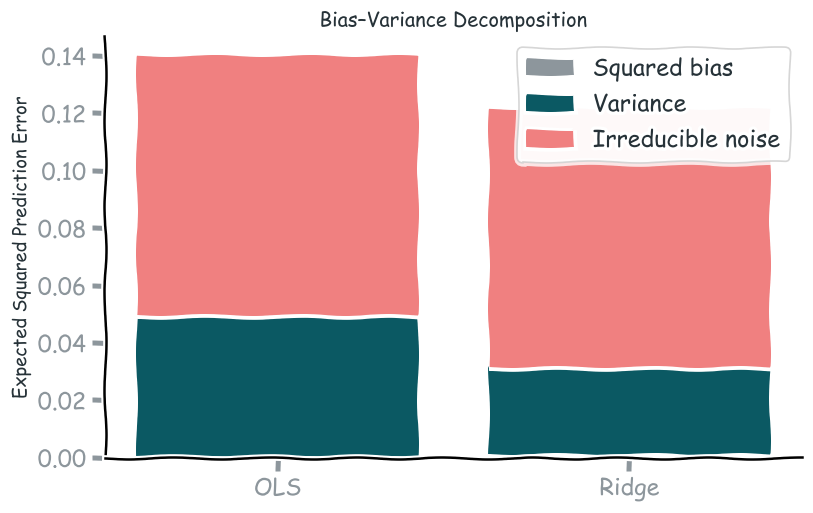

In [92]:
rng_bv = np.random.default_rng(BASE_SEED + 302)

n_repetitions = 200

# Fixed training input locations
X_fixed = X_train_reg

# Fixed evaluation grid
X_eval = X_grid

truth_eval = true_function(x_grid)

# Models
def new_ols_model():
    return make_polynomial_model(
        REG_DEGREE,
        LinearRegression()
    )


def new_ridge_model():
    return make_polynomial_model(
        REG_DEGREE,
        Ridge(alpha=best_ridge_alpha)
    )


predictions_ols = []
predictions_ridge = []

for _ in range(n_repetitions):

    # New noise realization
    y_repeated = (
        true_function(x_train_reg)
        + noise_std * rng_bv.standard_normal(n_train)
    )

    ols_model = new_ols_model()
    ridge_model = new_ridge_model()

    ols_model.fit(X_fixed, y_repeated)
    ridge_model.fit(X_fixed, y_repeated)

    predictions_ols.append(
        ols_model.predict(X_eval)
    )

    predictions_ridge.append(
        ridge_model.predict(X_eval)
    )

predictions_ols = np.asarray(predictions_ols)
predictions_ridge = np.asarray(predictions_ridge)

# Bias and variance estimates
def estimate_bias_variance(predictions, truth):

    mean_prediction = predictions.mean(axis=0)

    squared_bias = (
        mean_prediction - truth
    )**2

    variance = predictions.var(axis=0)

    return (
        np.mean(squared_bias),
        np.mean(variance)
    )


bias2_ols, var_ols = estimate_bias_variance(
    predictions_ols,
    truth_eval
)

bias2_ridge, var_ridge = estimate_bias_variance(
    predictions_ridge,
    truth_eval
)

print("Estimated bias-variance components")
print("-" * 50)

print(
    f"OLS:   Bias^2={bias2_ols:.5f}, "
    f"Variance={var_ols:.5f}"
)

print(
    f"Ridge: Bias^2={bias2_ridge:.5f}, "
    f"Variance={var_ridge:.5f}"
)

print(f"Irreducible noise variance: {noise_std**2:.5f}")

# Visualization
labels_bv = ["OLS", "Ridge"]

bias_values = [bias2_ols, bias2_ridge]
var_values = [var_ols, var_ridge]
noise_values = [noise_std**2, noise_std**2]

fig, ax = plt.subplots(figsize=(7, 4.5))

xpos = np.arange(len(labels_bv))

ax.bar(
    xpos,
    bias_values,
    color=GRAY,
    label="Squared bias"
)

ax.bar(
    xpos,
    var_values,
    bottom=bias_values,
    color=TEAL,
    label="Variance"
)

ax.bar(
    xpos,
    noise_values,
    bottom=np.array(bias_values) + np.array(var_values),
    color=RED,
    label="Irreducible noise"
)

ax.set_xticks(xpos)
ax.set_xticklabels(labels_bv)

ax.set_ylabel("Expected Squared Prediction Error")

ax.set_title(
    "Bias–Variance Decomposition"
)

ax.legend()

plt.tight_layout()
plt.show()

### 3.7 Optional: Beyond Global Polynomials: Splines

Polynomial regression uses global basis functions such as
$$
1,x,x^2,\ldots,x^p.
$$
A potential limitation is that changing a polynomial coefficient can affect predictions across the entire input domain.
High-degree polynomial models may also become numerically unstable or highly sensitive to individual observations.
An alternative is to use **piecewise polynomial basis functions**, commonly called splines.

Spline models divide the input domain using points known as knots.
Instead of fitting one high-degree polynomial across the entire domain, splines combine lower-degree polynomial functions with controlled smoothness at the knots.

Splines can provide:
- Flexible nonlinear relationships.
- Localized basis functions.
- Controlled smoothness.
- An alternative to high-degree global polynomial fitting.

They are especially useful when the underlying function changes differently across regions of the input domain.

We will use cubic B-spline features with ridge regression to illustrate the idea.

#### General Form

A spline-based regression model can be written as
$$
\hat f(x)=
\sum_{j=1}^{K}
\beta_jB_j(x),
$$
where $B_j(x)$ are spline basis functions.

The prediction remains linear in the coefficients $\beta_j$, even though the basis functions are nonlinear in $x$.


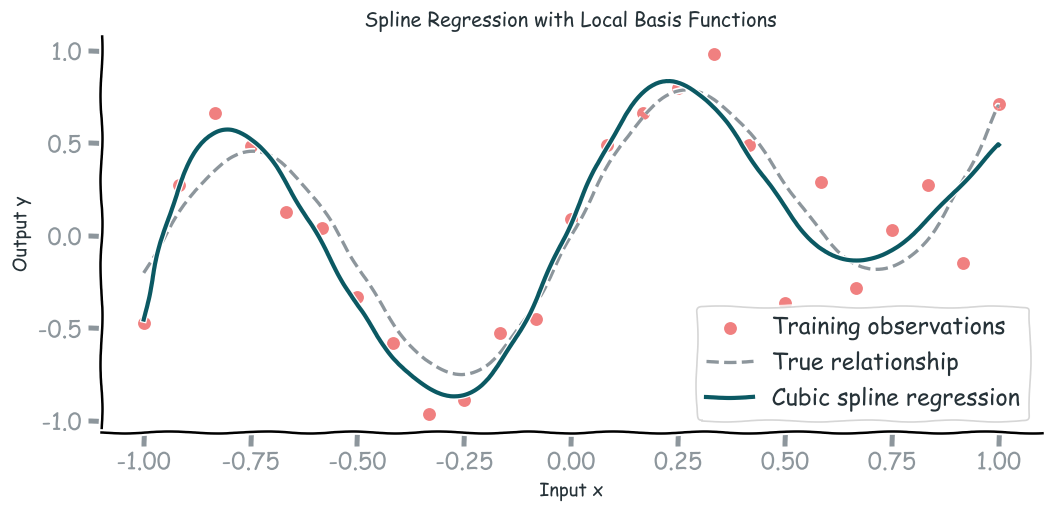

Spline training MSE: 0.03618
Spline validation MSE: 0.10264


In [93]:
from sklearn.preprocessing import SplineTransformer


spline_model = make_pipeline(
    SplineTransformer(
        n_knots=6,
        degree=3,
        include_bias=False
    ),
    StandardScaler(),
    Ridge(alpha=0.03)
)

spline_model.fit(X_train_reg, y_train_reg)

spline_train_mse = mean_squared_error(
    y_train_reg,
    spline_model.predict(X_train_reg)
)

spline_val_mse = mean_squared_error(
    y_val_reg,
    spline_model.predict(X_val_reg)
)

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.scatter(
    x_train_reg,
    y_train_reg,
    color=RED,
    s=45,
    label="Training observations"
)

ax.plot(
    x_grid,
    y_true_grid,
    color=GRAY,
    linestyle="--",
    lw=2,
    label="True relationship"
)

ax.plot(
    x_grid,
    spline_model.predict(X_grid),
    color=TEAL,
    lw=2.5,
    label="Cubic spline regression"
)

ax.set_xlabel("Input x")
ax.set_ylabel("Output y")

ax.set_title(
    "Spline Regression with Local Basis Functions"
)

ax.legend()
plt.tight_layout()
plt.show()

print(f"Spline training MSE: {spline_train_mse:.5f}")
print(f"Spline validation MSE: {spline_val_mse:.5f}")

### Experiment 3: Summary

In this experiment, we investigated regression, model complexity, regularization, and generalization.

The main lessons are:

1. Regression learns relationships between inputs and continuous outputs.
2. Nonlinear regression does not necessarily require nonlinear parameter estimation.
3. Increasing complexity improves flexibility but may reduce generalization.
4. Training error and validation error measure different quantities.
5. Regularization controls coefficient complexity.
6. Regularization introduces a bias–variance trade-off.
7. Numerical conditioning matters.
8. Model selection should not use test data.

We selected model complexity and regularization strength using validation data and reserved the test set for final evaluation.


# Part IV: Generalization

## Experiment 4: Can Data Splitting Mislead Us?

Throughout the previous experiments, we have emphasized the importance of evaluating machine learning models on observations that were not used during training.
However, there is an important question that we have not fully addressed:

**What does it mean for an observation to be new?**

In signal processing applications, observations are frequently correlated.

For example:
- Consecutive ECG heartbeats originate from the same patient.
- Overlapping windows extracted from a vibration recording share signal samples.
- Adjacent time windows in telecommunications traffic may exhibit similar temporal patterns.
- Measurements collected from the same physical system may share operating conditions and systematic errors.

As a result, randomly dividing individual observations into training and testing sets may not always provide an appropriate evaluation of generalization.
In this experiment, we will investigate how different data-splitting strategies affect the apparent performance of the same machine learning algorithm.  

*We will reuse the ECG features and logistic regression classifier introduced in Experiment 2.*


### 4.1 The Problem

Consider a dataset containing several ECG recordings.
From each recording, we extract hundreds or thousands of annotated heartbeats.
Each heartbeat is represented by a feature vector:
$$
\mathbf x_i\in\mathbb R^d.
$$
The corresponding class label is
$$
y_i\in\{0,1\}.
$$
However, observations also have an additional property:  
**Each heartbeat belongs to a particular recording.**

Let
$$
g_i\in\{1,\ldots,G\}
$$
denote the recording associated with observation $i$.
The complete dataset can therefore be represented as
$$
\mathcal D=
\{(\mathbf x_i,y_i,g_i)\}_{i=1}^{M}.
$$

*Why Does the Recording Identity Matter?*

Heartbeats from the same recording may share:
- Patient-specific ECG morphology.
- Similar heart-rate patterns.
- Measurement characteristics.
- Baseline and amplitude characteristics.
- Temporal dependencies.

Consequently, two beats extracted from the same recording may be statistically more similar than two beats extracted from different recordings.

#### Two Different Generalization Questions

**Question A — New Beats from Familiar Recordings**  
How well can the model classify unseen beats from recordings that were also represented during training?

**Question B — Beats from Unseen Recordings**  
How well can the model classify beats from recordings that were completely absent during training?

These are different prediction problems.
A model may perform well on Question A while performing less reliably on Question B.
The appropriate evaluation procedure depends on which question corresponds to the intended application.

> A test set should represent the type of unseen data on which the model is expected to operate.

### 4.2. Comparing Two Data-Splitting Strategies

We will evaluate the same logistic regression approach using two different splitting strategies.

#### Strategy A: Random Beat-Level Split

Individual heartbeats are randomly assigned to training and evaluation sets.
The split is stratified by class label to approximately preserve the overall class proportions.
Because beats are split individually, observations from the same recording may appear in both sets.
This evaluates performance on held-out beats from recordings that are also represented during training.

#### Strategy B: Recording-Separated Split

Entire recordings are assigned to either training or evaluation.  
No recording contributes beats to both partitions.  
This evaluates performance on recordings that were not represented during model fitting.

#### Comparison

| Property | Random beat-level | Recording-separated |
|---|---|---|
| Split unit | Individual heartbeat | Complete recording |
| Recording overlap | Allowed | Not allowed |
| Class proportions | Can be approximately preserved | Depend on selected recordings |
| Evaluation target | New beats from familiar recordings | Beats from unseen recordings |
| Main concern | Correlated observations across partitions | Variation between recordings |

Neither strategy is universally correct.

The distinction depends on what kind of generalization we want to measure.

#### Experiment Design

To make the comparison easier to interpret:
1. Both strategies will use the same six development recordings.
2. Both will use the same seven ECG features.
3. Both will use logistic regression with identical hyperparameters.
4. Feature standardization will be fitted separately using each strategy's training data.
5. Both strategies will use the same number of training and evaluation observations.
6. We will compare threshold-dependent and threshold-independent metrics.

The resulting evaluation sets will not contain the same observations.
Therefore, differences in performance may reflect both the evaluation protocol and differences in the distributions of the selected evaluation observations.
We should not interpret the comparison as a controlled causal estimate of the effect of leakage alone.

> **Q4:** Can We Trust the Test Accuracy?  
>Suppose an ECG classifier achieves excellent test accuracy after randomly dividing heartbeats into training and test sets. However, both sets contain heartbeats extracted from the same recordings.
> 1. Does this result demonstrate that the classifier will perform equally well on completely new patients?
> 2. What information might the classifier exploit when training and evaluation beats come from the same recording?
> 3. How could we design a more appropriate evaluation?  

#### Generalization and data splitting

In [94]:
from sklearn.model_selection import train_test_split

# Use only the development recordings from Experiment 2
iv_record_ids = TRAIN_RECORDS + VAL_RECORDS

iv_dev_mask = np.isin(
    groups_ecg,
    iv_record_ids
)

iv_X = X_ecg[iv_dev_mask]
iv_y = y_ecg[iv_dev_mask]
iv_groups = groups_ecg[iv_dev_mask]

iv_indices = np.arange(len(iv_y))

# Strategy A: Random beat-level split
iv_n_eval = np.sum(
    np.isin(iv_groups, VAL_RECORDS)
)

iv_random_train_idx, iv_random_eval_idx = train_test_split(
    iv_indices,
    test_size=int(iv_n_eval),
    stratify=iv_y,
    random_state=BASE_SEED + 401
)

# Strategy B: Recording-separated split
iv_group_train_idx = np.flatnonzero(
    np.isin(iv_groups, TRAIN_RECORDS)
)

iv_group_eval_idx = np.flatnonzero(
    np.isin(iv_groups, VAL_RECORDS)
)

# Store the protocols
iv_splits = {
    "Random beat-level": (
        iv_random_train_idx,
        iv_random_eval_idx
    ),
    "Recording-separated": (
        iv_group_train_idx,
        iv_group_eval_idx
    )
}

# Verification
for name, (train_idx, eval_idx) in iv_splits.items():

    assert len(np.intersect1d(train_idx, eval_idx)) == 0

    assert len(train_idx) + len(eval_idx) == len(iv_y)

    assert len(train_idx) == len(iv_group_train_idx)
    assert len(eval_idx) == len(iv_group_eval_idx)

    assert set(np.unique(iv_y[train_idx])) == {0, 1}
    assert set(np.unique(iv_y[eval_idx])) == {0, 1}

    train_records = set(iv_groups[train_idx])
    eval_records = set(iv_groups[eval_idx])

    overlap = train_records.intersection(eval_records)

    print(f"\n{name}")
    print("-" * 50)

    print(f"Training beats: {len(train_idx)}")
    print(f"Evaluation beats: {len(eval_idx)}")

    print(
        f"Training PVC prevalence: "
        f"{np.mean(iv_y[train_idx]):.3f}"
    )

    print(
        f"Evaluation PVC prevalence: "
        f"{np.mean(iv_y[eval_idx]):.3f}"
    )

    print(f"Training recordings: {sorted(train_records)}")
    print(f"Evaluation recordings: {sorted(eval_records)}")
    print(f"Shared recordings: {sorted(overlap)}")

# Recording-separated strategy must contain no overlapping records
assert set(
    iv_groups[iv_group_train_idx]
).isdisjoint(
    iv_groups[iv_group_eval_idx]
)

print("\nSplit verification completed.")


Random beat-level
--------------------------------------------------
Training beats: 8817
Evaluation beats: 5398
Training PVC prevalence: 0.185
Evaluation PVC prevalence: 0.185
Training recordings: [np.str_('100'), np.str_('106'), np.str_('119'), np.str_('200'), np.str_('203'), np.str_('221')]
Evaluation recordings: [np.str_('100'), np.str_('106'), np.str_('119'), np.str_('200'), np.str_('203'), np.str_('221')]
Shared recordings: [np.str_('100'), np.str_('106'), np.str_('119'), np.str_('200'), np.str_('203'), np.str_('221')]

Recording-separated
--------------------------------------------------
Training beats: 8817
Evaluation beats: 5398
Training PVC prevalence: 0.203
Evaluation PVC prevalence: 0.156
Training recordings: [np.str_('100'), np.str_('106'), np.str_('119'), np.str_('200')]
Evaluation recordings: [np.str_('203'), np.str_('221')]
Shared recordings: []

Split verification completed.


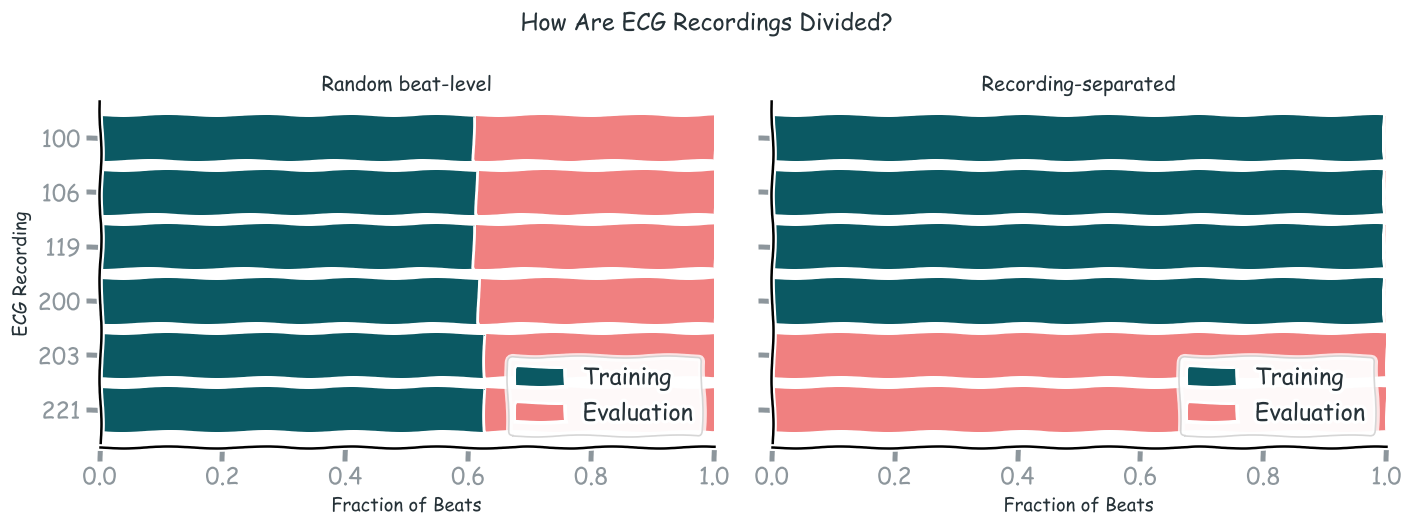

In [96]:
record_order = TRAIN_RECORDS + VAL_RECORDS

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharey=True
)

for ax, (name, (train_idx, eval_idx)) in zip(
    axes, iv_splits.items()
):

    train_mask = np.zeros(len(iv_y), dtype=bool)
    eval_mask = np.zeros(len(iv_y), dtype=bool)

    train_mask[train_idx] = True
    eval_mask[eval_idx] = True

    train_fraction = []
    eval_fraction = []

    for rid in record_order:

        record_mask = iv_groups == rid

        train_fraction.append(
            np.mean(train_mask[record_mask])
        )

        eval_fraction.append(
            np.mean(eval_mask[record_mask])
        )

    train_fraction = np.asarray(train_fraction)
    eval_fraction = np.asarray(eval_fraction)

    ypos = np.arange(len(record_order))

    ax.barh(
        ypos,
        train_fraction,
        color=TEAL,
        label="Training"
    )

    ax.barh(
        ypos,
        eval_fraction,
        left=train_fraction,
        color=RED,
        label="Evaluation"
    )

    ax.set_yticks(ypos)
    ax.set_yticklabels(record_order)

    ax.set_xlim(0, 1)
    ax.set_xlabel("Fraction of Beats")

    ax.set_title(name)
    ax.legend(loc="lower right")

axes[0].set_ylabel("ECG Recording")
axes[0].invert_yaxis()

plt.suptitle(
    "How Are ECG Recordings Divided?",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 4.3. Evaluating the Same Learning Algorithm

We now train logistic regression under the two splitting strategies.
The model is:
$$
P(Y=1|\mathbf x)=
\sigma(\mathbf w^T\mathbf x+b).
$$
We will use the same:
- Seven ECG features.
- Feature standardization procedure.
- Logistic regression implementation.
- Regularization parameter.
- Classification threshold.

The only intentional change is the data-splitting protocol.


#### Evaluation Metrics

We will calculate:

**Accuracy:** The overall fraction of correct classifications.

**ROC-AUC:** How well the learned scores rank positive beats above negative beats.

**Average Precision (AP):** A summary of precision–recall performance.

**Recall:** The fraction of actual PVC beats detected.

**False-Positive Rate:** The fraction of normal beats incorrectly classified as PVC.

**Note:**  
>Feature standardization must be learned independently within each training partition. We will use a scikit-learn pipeline:
>$$
>\boxed{
>\text{StandardScaler}
>\rightarrow
>\text{LogisticRegression}
>}
>$$
>This prevents information from the evaluation features from being used to estimate training-time scaling parameters.The purpose of this comparison is to investigate different generalization settings, not to maximize classifier performance.

#### Fit and Evaluate Both Models

In [97]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

IV_C = 0.05
IV_THRESHOLD = 0.5

iv_models = {}
iv_results = {}

for name, (train_idx, eval_idx) in iv_splits.items():

    X_tr = iv_X[train_idx]
    y_tr = iv_y[train_idx]

    X_ev = iv_X[eval_idx]
    y_ev = iv_y[eval_idx]

    # New pipeline for each split
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=IV_C,
            penalty="l2",
            max_iter=3000,
            random_state=BASE_SEED
        )
    )

    model.fit(X_tr, y_tr)

    # Predicted probabilities and decisions
    scores = model.predict_proba(X_ev)[:, 1]

    predictions = (
        scores >= IV_THRESHOLD
    ).astype(int)

    # Confusion-matrix quantities
    tn, fp, fn, tp = confusion_matrix(
        y_ev,
        predictions,
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)

    # Evaluation metrics
    metrics = {
        "Accuracy": accuracy_score(y_ev, predictions),
        "ROC-AUC": roc_auc_score(y_ev, scores),
        "AP": average_precision_score(y_ev, scores),
        "Precision": precision_score(
            y_ev, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_ev, predictions, zero_division=0
        ),
        "FPR": fpr
    }

    iv_models[name] = model

    iv_results[name] = {
        "y_true": y_ev,
        "scores": scores,
        "predictions": predictions,
        "groups": iv_groups[eval_idx],
        "prevalence": np.mean(y_ev),
        "metrics": metrics
    }

# Print comparison
print("Evaluation Protocol Comparison")
print("-" * 75)

print(
    f"{'Metric':<18}"
    f"{'Random Beat-Level':>22}"
    f"{'Recording-Separated':>24}"
)

metric_names = [
    "Accuracy",
    "ROC-AUC",
    "AP",
    "Precision",
    "Recall",
    "FPR"
]

for metric in metric_names:

    value_random = iv_results[
        "Random beat-level"
    ]["metrics"][metric]

    value_group = iv_results[
        "Recording-separated"
    ]["metrics"][metric]

    print(
        f"{metric:<18}"
        f"{value_random:>22.4f}"
        f"{value_group:>24.4f}"
    )

print("\nPositive-class prevalence:")

for name, result in iv_results.items():
    print(f"{name}: {result['prevalence']:.4f}")

Evaluation Protocol Comparison
---------------------------------------------------------------------------
Metric                 Random Beat-Level     Recording-Separated
Accuracy                          0.9657                  0.7716
ROC-AUC                           0.9913                  0.9707
AP                                0.9466                  0.8029
Precision                         0.9111                  0.4047
Recall                            0.9029                  0.9929
FPR                               0.0200                  0.2692

Positive-class prevalence:
Random beat-level: 0.1851
Recording-separated: 0.1556


#### Compare ROC and Precision–Recall Curves

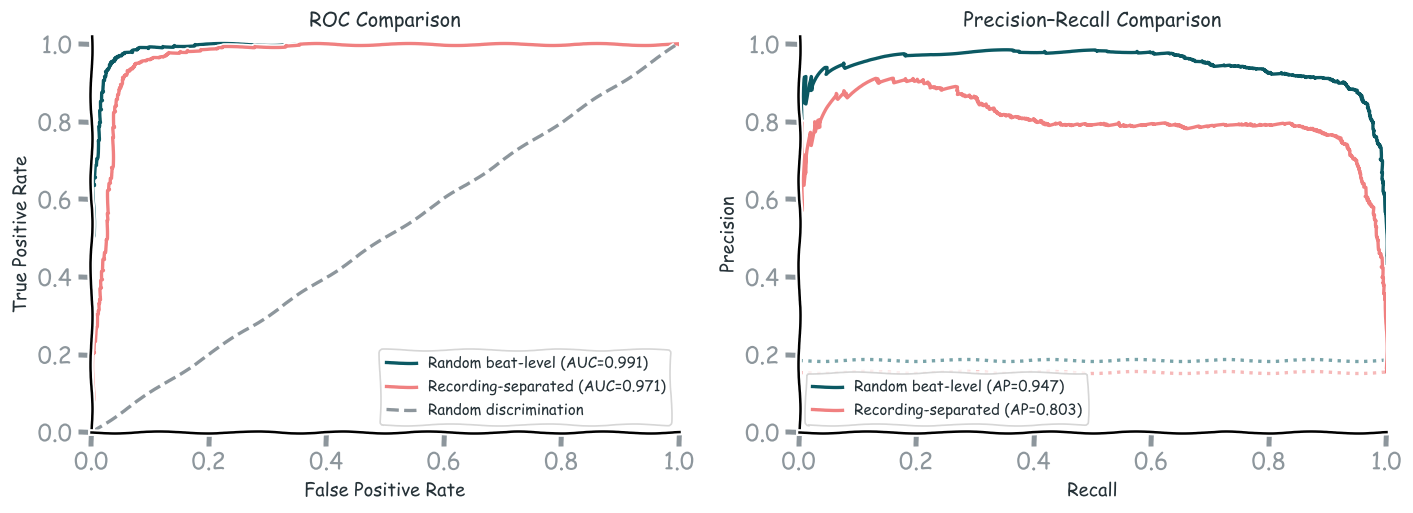

In [98]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5)
)

plot_colors = {
    "Random beat-level": TEAL,
    "Recording-separated": RED
}

for name, result in iv_results.items():

    y_true = result["y_true"]
    scores = result["scores"]

    color = plot_colors[name]

    # ROC
    fpr, tpr, _ = roc_curve(
        y_true, scores
    )

    auc = result["metrics"]["ROC-AUC"]

    axes[0].plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{name} (AUC={auc:.3f})"
    )

    # Precision-recall
    precision, recall, _ = precision_recall_curve(
        y_true, scores
    )

    ap = result["metrics"]["AP"]

    axes[1].plot(
        recall,
        precision,
        color=color,
        lw=2,
        label=f"{name} (AP={ap:.3f})"
    )

    # Prevalence reference for each evaluation set
    axes[1].axhline(
        result["prevalence"],
        color=color,
        linestyle=":",
        alpha=0.55
    )

# ROC reference
axes[0].plot(
    [0, 1],
    [0, 1],
    color=GRAY,
    linestyle="--",
    label="Random discrimination"
)

axes[0].set_title("ROC Comparison")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")

axes[1].set_title("Precision–Recall Comparison")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

### 4.4. Looking Beyond Aggregate Performance

Aggregate evaluation metrics summarize performance across many observations.
However, in signal processing, observations often belong to different physical systems, subjects, or recording sessions.
This raises another question:

**Does strong overall performance imply equally strong performance for every recording?**  
In Experiment 2, we observed substantial differences between recordings.

For example, the same classification threshold produced very different false-positive rates on two validation recordings.
We will now examine recording-level performance for the recording-separated model in the current experiment.
Unlike aggregate ROC-AUC, recording-level metrics reveal variability across individual recording conditions.
However, individual recording estimates may themselves be uncertain, especially when a recording contains relatively few examples of one class.

#### Recording-Level Performance

In [99]:
result = iv_results["Recording-separated"]

y_eval = result["y_true"]
scores_eval = result["scores"]
pred_eval = result["predictions"]
groups_eval = result["groups"]

print("Recording-Level Performance")
print("-" * 80)

print(
    f"{'Record':<10}"
    f"{'Beats':>10}"
    f"{'PVC %':>10}"
    f"{'AUC':>10}"
    f"{'AP':>10}"
    f"{'FPR':>10}"
    f"{'Recall':>10}"
)

for rid in np.unique(groups_eval):

    mask = groups_eval == rid

    yt = y_eval[mask]
    st = scores_eval[mask]
    yp = pred_eval[mask]

    tn, fp, fn, tp = confusion_matrix(
        yt, yp, labels=[0, 1]
    ).ravel()

    auc = roc_auc_score(yt, st)
    ap = average_precision_score(yt, st)

    fpr = fp / (fp + tn)
    recall = tp / (tp + fn)

    print(
        f"{rid:<10}"
        f"{len(yt):>10d}"
        f"{100 * np.mean(yt):>9.1f}%"
        f"{auc:>10.4f}"
        f"{ap:>10.4f}"
        f"{fpr:>10.4f}"
        f"{recall:>10.4f}"
    )

Recording-Level Performance
--------------------------------------------------------------------------------
Record         Beats     PVC %       AUC        AP       FPR    Recall
203             2972     14.9%    0.9544    0.7843    0.4854    0.9865
221             2426     16.3%    1.0000    1.0000    0.0000    1.0000


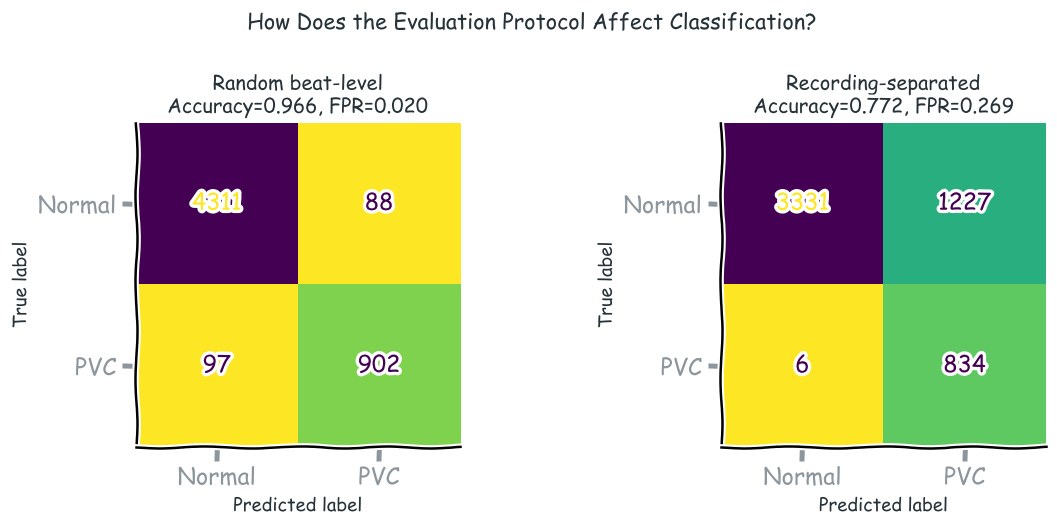

In [103]:
from sklearn.metrics import ConfusionMatrixDisplay
from matplotlib.colors import LinearSegmentedColormap

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, (name, result) in zip(
    axes, iv_results.items()
):

    ConfusionMatrixDisplay.from_predictions(
        result["y_true"],
        result["predictions"],
        labels=[0, 1],
        display_labels=["Normal", "PVC"],
        cmap="viridis_r",
        colorbar=False,
        values_format="d",
        ax=ax
    )

    accuracy = result["metrics"]["Accuracy"]
    fpr = result["metrics"]["FPR"]

    ax.set_title(
        f"{name}\n"
        f"Accuracy={accuracy:.3f}, FPR={fpr:.3f}"
    )

plt.suptitle(
    "How Does the Evaluation Protocol Affect Classification?",
    fontsize=13
)

plt.tight_layout()
plt.show()

### Experiment 4 Summary

We evaluated the same logistic regression approach using two different data-splitting strategies.
The results revealed substantial differences in classification performance.

**Random Beat-Level Evaluation**  
- When individual heartbeats were randomly divided into training and evaluation sets, the classifier achieved:  
  - Accuracy: 96.57%  
  - ROC-AUC: 0.9913  
  - False-positive rate: 2.00%  

However, all six ECG recordings contributed observations to both partitions.
The classifier was therefore evaluated on unseen beats from recordings whose characteristics were already represented during training.

**Recording-Separated Evaluation**  
- When entire recordings were excluded from training, the classifier achieved:  
  - Accuracy: 77.16%  
  - ROC-AUC: 0.9707  
  - False-positive rate: 26.92%

Although the classifier maintained relatively strong discrimination, its false-positive rate increased substantially.
This illustrates that high performance on randomly held-out observations does not necessarily imply equally strong performance on entirely unseen recordings.

***Why Did Performance Change?***

Heartbeats from the same recording may share patient-specific morphology, measurement characteristics, and temporal patterns.
When a recording appears in both training and evaluation, the classifier may benefit from these familiar characteristics.
When evaluated on an unseen recording, the feature distribution may differ from what the classifier encountered during training.

However, the two evaluation sets also differ in their recording composition and class prevalence. Therefore, we cannot attribute the entire performance difference exclusively to statistical dependence or data leakage.


*A model's reported performance is only meaningful when the evaluation data represent the type of unseen observations the model is expected to encounter.*

A reliable machine learning experiment must evaluate not only whether a model has learned useful patterns, but also whether those patterns generalize beyond the specific observations and conditions used during training.